In [ ]:
import pandas as pd
from IPython.display import display, Markdown
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import os
os.makedirs('figuras', exist_ok=True)
os.makedirs('tabelas', exist_ok=True)

# Fonte indicada abaixo de cada gráfico e tabela
FONTE = ('Fonte: elaboração própria em Python, com auxílio de inteligência artificial, '
         'a partir dos dados de Fanaee-T (2013), UCI Machine Learning Repository.')

import textwrap

def nota_grafico():
    fig = plt.gcf()
    largura = int(fig.get_size_inches()[0] * 15)   # quebra o texto conforme a largura da figura
    fig.text(0.01, -0.01, textwrap.fill(FONTE, largura), ha='left', va='top', fontsize=9, style='italic')


In [ ]:
file_path = 'hour.csv'
# lembrar de subir no github o hour.csv

df = pd.read_csv(file_path)
df.head()

### Uso do df.head para inspecionar rapidamente os dados e os nomes das primeiras colunas

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [ ]:
df.shape

(17379, 17)

In [ ]:
## Utilizando um comando para exibir um resumo geral e rápido da estrutura do nosso dataset.

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [ ]:
# Verificando se casual + registered = cnt em todas as linhas (resultado esperado: 0)
(df['casual'] + df['registered'] != df['cnt']).sum()

np.int64(0)

A base tem 17.379 registros e 17 variáveis, sem valores nulos explícitos. O que por si só, é algo estranho, pois 2011 (365 dias) com 2012 (366 dias) totaliza 731 dias, multiplicado por 24h dá 17.544 e nós temos apenas 17.379 linhas, que nos totaliza 165 horas faltantes.
A soma 'casual' + 'registered' = 'cnt' é consistente em todas as linhas.



In [ ]:
df['dteday'] = pd.to_datetime(df['dteday'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
instant,17379.0,8690.0,1.0,4345.5,8690.0,13034.5,17379.0,5017.0295
dteday,17379,2012-01-02 04:08:34.552045,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357


In [ ]:
### Nesse projeto, é válido lembrar que: A umidade de um ambiente não pode nunca ser 0, os meses variam de 1 a 12 em ordem e o horário varia de 00h a 23h.
### Faremos nossas análises em cima disso. Logo, vamos fazer uma limpeza em cima desses dados.

In [ ]:
(df['hum'] == 0).sum()

## usamos para saber quantas linhas possuem umidade = 0


np.int64(22)

In [ ]:
df[df['hum'] == 0]

## usamos para saber QUAIS as linhas que possuem umidade = 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
1551,1552,2011-03-10,1,0,3,0,0,4,1,3,0.34,0.3182,0.0,0.2537,3,0,3
1552,1553,2011-03-10,1,0,3,1,0,4,1,3,0.34,0.3182,0.0,0.2537,0,2,2
1553,1554,2011-03-10,1,0,3,2,0,4,1,3,0.34,0.3182,0.0,0.2537,0,1,1
1554,1555,2011-03-10,1,0,3,5,0,4,1,3,0.36,0.3485,0.0,0.1940,1,2,3
1555,1556,2011-03-10,1,0,3,6,0,4,1,3,0.36,0.3333,0.0,0.3284,0,12,12
1556,1557,2011-03-10,1,0,3,7,0,4,1,3,0.38,0.3939,0.0,0.2239,1,36,37
1557,1558,2011-03-10,1,0,3,8,0,4,1,3,0.38,0.3939,0.0,0.2836,1,43,44
1558,1559,2011-03-10,1,0,3,9,0,4,1,3,0.40,0.4091,0.0,0.2239,1,23,24
1559,1560,2011-03-10,1,0,3,10,0,4,1,3,0.40,0.4091,0.0,0.1642,0,17,17
1560,1561,2011-03-10,1,0,3,11,0,4,1,3,0.40,0.4091,0.0,0.2537,6,5,11


In [ ]:
### Percebemos aqui que todos os dados que possuem umidade = 0 foram registrados no mesmo dia. Isso provavelmente é um erro do sensor,
### ou não foram registrados dados de umidade nesse dia. É o que chamamos de dado ausente disfarçado: o valor está preenchido, mas não é real.

In [ ]:
df['weathersit'].value_counts().sort_index()

weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64

A categoria 4 de weathersit (chuva forte) tem apenas 3 registros. Será agrupada com a categoria 3.

In [ ]:
horas_por_dia = df.groupby('dteday').size()
horas_por_dia

dteday
2011-01-01    24
2011-01-02    23
2011-01-03    22
2011-01-04    23
2011-01-05    23
              ..
2012-12-27    24
2012-12-28    24
2012-12-29    24
2012-12-30    24
2012-12-31    24
Length: 731, dtype: int64

In [ ]:
(horas_por_dia < 24).sum()

## para vermos quantos dias estão incompletos

np.int64(76)

In [ ]:
horas_por_dia.sort_values().head(10)

dteday
2012-10-29     1
2011-01-27     8
2012-10-30    11
2011-01-18    12
2011-01-26    16
2011-08-28    17
2011-02-22    18
2011-08-27    18
2011-01-11    22
2011-02-28    22
dtype: int64

In [ ]:
## Faltam 165 horas, distribuídas em 76 dias. Os casos extremos são 29/10/2012 (1 hora) e 30/10/2012 (11 horas),
## durante o furacão Sandy, quando o serviço foi suspenso. Essas horas não serão preenchidas.

In [ ]:
df.duplicated(subset=['dteday', 'hr']).sum()

## para saber se alguma linha envolvendo dia e hora aparece repetida na tabela

np.int64(0)

In [ ]:
## Não há linhas duplicadas (nenhuma combinação de data e hora se repete).

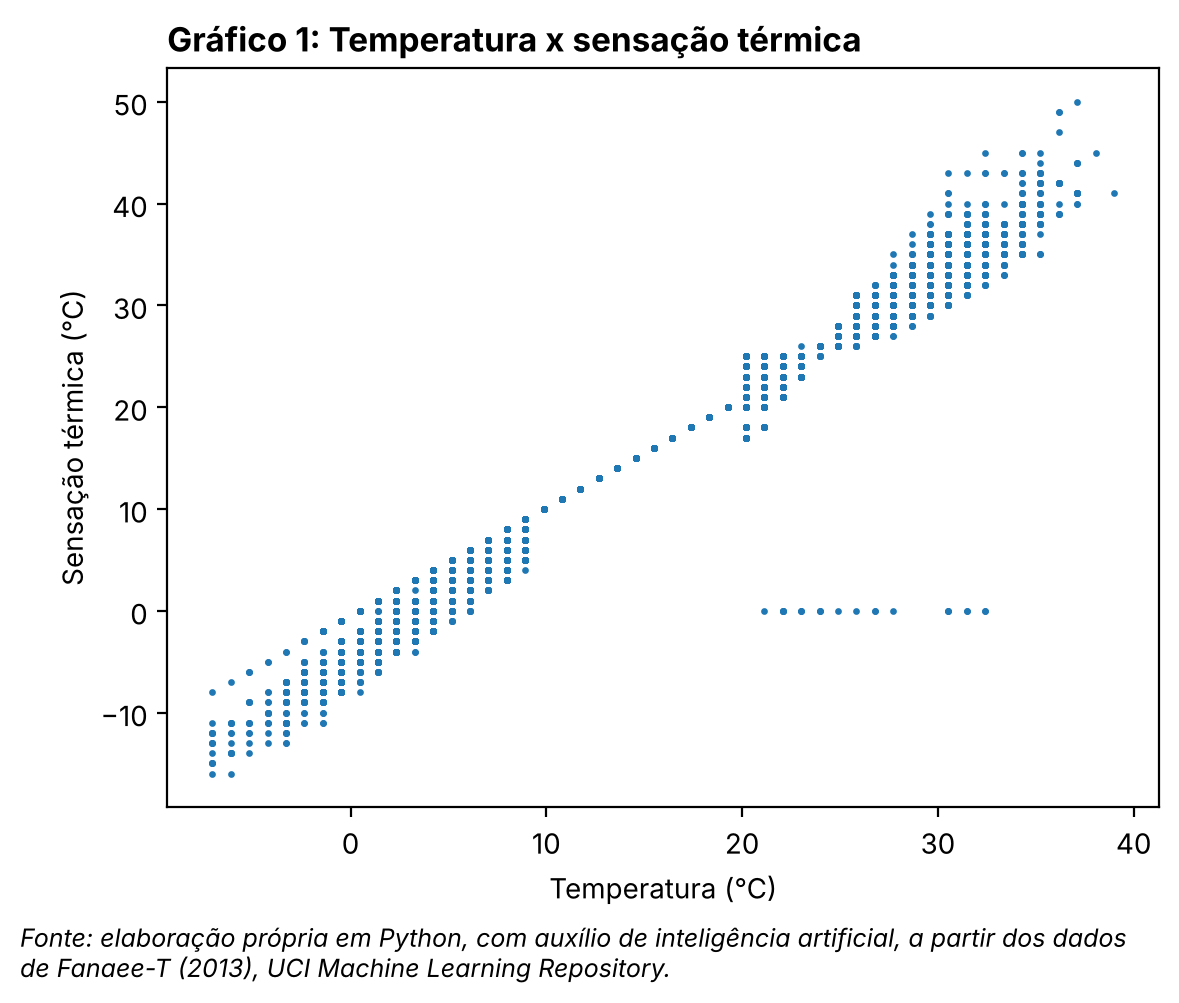

In [ ]:
### Agora, queremos analisar as colunas 'temp' e 'atemp' para analisar possíveis erros. Gerando um gráfico (já convertido para celsius) de dispersão entre elas , temos:

# Número do gráfico no relatório
numero_grafico = 1

df['temp_c'] = df['temp'] * 47 - 8
df['atemp_c'] = df['atemp'] * 66 - 16

plt.scatter(df['temp_c'], df['atemp_c'], s=2)
plt.xlabel('Temperatura (°C)')
plt.ylabel('Sensação térmica (°C)')
plt.title(
    f'Gráfico {numero_grafico}: Temperatura x sensação térmica',
    fontweight='bold', loc='left'
)
nota_grafico()
plt.savefig(f'figuras/grafico_{numero_grafico}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Para encontrar a data em que os pontos que fogem da relação esperada entre 'temp' e 'atemp', usaremos:

df[(df['temp'] > 0.6) & (df['atemp'] < 0.3)][['dteday', 'hr', 'temp', 'atemp']]

,dteday,hr,temp,atemp
14131,2012-08-17,0,0.68,0.2424
14132,2012-08-17,1,0.66,0.2424
14133,2012-08-17,2,0.66,0.2424
14134,2012-08-17,3,0.64,0.2424
14135,2012-08-17,4,0.64,0.2424
14136,2012-08-17,5,0.64,0.2424
14137,2012-08-17,6,0.62,0.2424
14138,2012-08-17,7,0.64,0.2424
14139,2012-08-17,8,0.68,0.2424
14140,2012-08-17,9,0.70,0.2424


In [ ]:
### E assim, encontramos que 'atemp' está travada em 0,24 durante o dia 17/08/2012, o que é incompatível com 'temp'.
### Como 'atemp' acompanha 'temp' quase perfeitamente, a coluna será descartada e só 'temp' será usada.

# LIMPEZA DOS DADOS E MEDIDAS DESCRITIVAS


In [ ]:
df_modelo = df.copy()

# 1. Umidade zero: marcar como ausente e estimar pelas horas vizinhas
df_modelo.loc[df_modelo['hum'] == 0, 'hum'] = np.nan
df_modelo['hum'] = df_modelo['hum'].interpolate()

# 2. Juntar a categoria 4 do clima com a categoria 3
df_modelo['weathersit'] = df_modelo['weathersit'].replace(4, 3)

In [ ]:
## Conferindo a limpeza
print('Umidade igual a zero:', (df_modelo['hum'] == 0).sum())
print('Umidade ausente (NaN):', df_modelo['hum'].isna().sum())
print(df_modelo['weathersit'].value_counts().sort_index())

Umidade igual a zero: 0
Umidade ausente (NaN): 0
weathersit
1    11413
2     4544
3     1422
Name: count, dtype: int64


In [ ]:
# Número da tabela no relatório
numero_tabela = 1

desc = pd.DataFrame({
    'Aluguéis por hora (cnt)': df_modelo['cnt'],
    'Usuários casuais': df_modelo['casual'],
    'Usuários registrados': df_modelo['registered'],
    'Temperatura (°C)': df_modelo['temp'] * 47 - 8,
    'Umidade (%)': df_modelo['hum'] * 100,
    'Vento (km/h)': df_modelo['windspeed'] * 67,
}).describe().T[['mean', '50%', 'std', 'min', 'max']]
desc.columns = ['Média', 'Mediana', 'Desvio padrão', 'Mínimo', 'Máximo']

# Exportar para o relatório
desc.round(1).to_csv(f'tabelas/tabela_{numero_tabela}.csv')

tabela_exibida = desc.style.format(lambda v: f'{v:.1f}'.replace('.', ',')).set_caption(
    f'Tabela {numero_tabela}: Medidas descritivas das principais variáveis (2011–2012).'
)

display(tabela_exibida)
display(Markdown(f'*{FONTE}*'))


,Média,Mediana,Desvio padrão,Mínimo,Máximo
Aluguéis por hora (cnt),"189,5","142,0","181,4","1,0","977,0"
Usuários casuais,"35,7","17,0","49,3","0,0","367,0"
Usuários registrados,"153,8","115,0","151,4","0,0","886,0"
Temperatura (°C),"15,4","15,5","9,1","-7,1","39,0"
Umidade (%),"62,8","63,0","19,2","8,0","100,0"
Vento (km/h),"12,7","13,0","8,2","0,0","57,0"


*Fonte: elaboração própria em Python, com auxílio de inteligência artificial, a partir dos dados de Fanaee-T (2013), UCI Machine Learning Repository.*

# ------------- MOTIVAÇÃO PARA ANÁLISE 1: Em que horas do dia as pessoas mais alugam bicicletas, e esse padrão se mantém de 2011 para 2012?  -----------

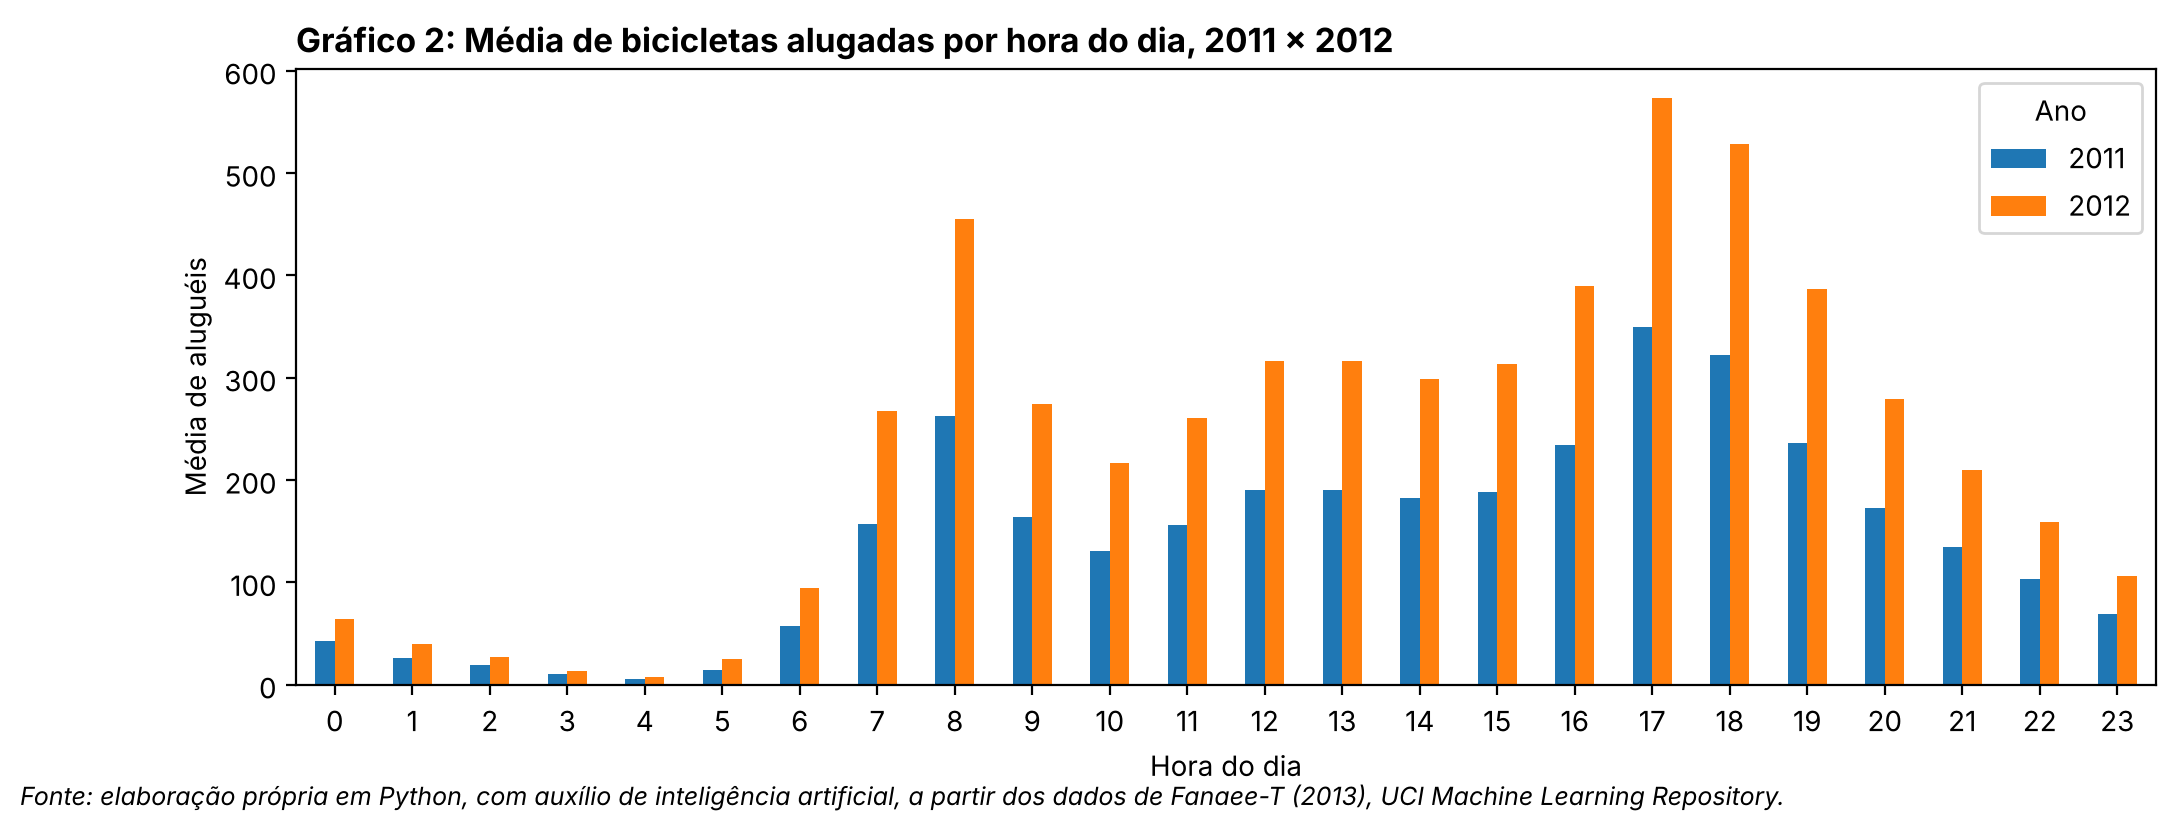

In [ ]:
# Número do gráfico no relatório
numero_grafico = 2

media_hora_ano = df.groupby(['hr', 'yr'])['cnt'].mean().unstack()
media_hora_ano.columns = ['2011', '2012']

media_hora_ano.plot(kind='bar', figsize=(12, 4))
plt.title(
    f'Gráfico {numero_grafico}: Média de bicicletas alugadas por hora do dia, 2011 x 2012',
    fontweight='bold', loc='left'
)
plt.xlabel('Hora do dia')
plt.ylabel('Média de aluguéis')
plt.xticks(rotation=0)
plt.legend(title='Ano')
nota_grafico()
plt.savefig(f'figuras/grafico_{numero_grafico}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
## Percebemos uma coisa: a média de bicicletas alugadas por hora do dia em 2012 foi maior do que em 2011, mas vale lembrar:
## Em 2012 houve mais aluguéis de bicicleta do que em 2011. Com o código abaixo, conseguimos ver que: para cada hora, quantas vezes a demanda de aluguel de 2012 é maior que a de 2011

print((media_hora_ano['2012'] / media_hora_ano['2011']).round(2))

media_ano = df.groupby('yr')['cnt'].mean()
print(f'Média por hora: 2011 = {media_ano[0]:.1f} | 2012 = {media_ano[1]:.1f} | '
      f'crescimento = {(media_ano[1] / media_ano[0] - 1) * 100:.0f}%')

hr
0     1.50
1     1.51
2     1.41
3     1.33
4     1.35
5     1.71
6     1.64
7     1.70
8     1.73
9     1.68
10    1.65
11    1.67
12    1.67
13    1.66
14    1.64
15    1.67
16    1.66
17    1.64
18    1.64
19    1.63
20    1.61
21    1.56
22    1.53
23    1.54
dtype: float64
Média por hora: 2011 = 143.8 | 2012 = 234.7 | crescimento = 63%


In [ ]:
### Conclusão da Análise 1

### A demanda varia fortemente ao longo do dia, com dois picos, por volta das 8h e das 17h–18h, compatíveis com o deslocamento casa–trabalho,
### e demanda mínima de madrugada. O padrão horário é o mesmo em 2011 e 2012, mas a demanda média cresceu cerca de 63% de um ano para o outro,
### de forma generalizada em todas as horas, o que indica a expansão do sistema. Portanto, hr e yr devem ser variáveis importantes para prever cnt.

# --------------------- MOTIVAÇÃO PARA ANÁLISE 2: A demanda por bicicletas muda conforme a estação do ano? ---------------------

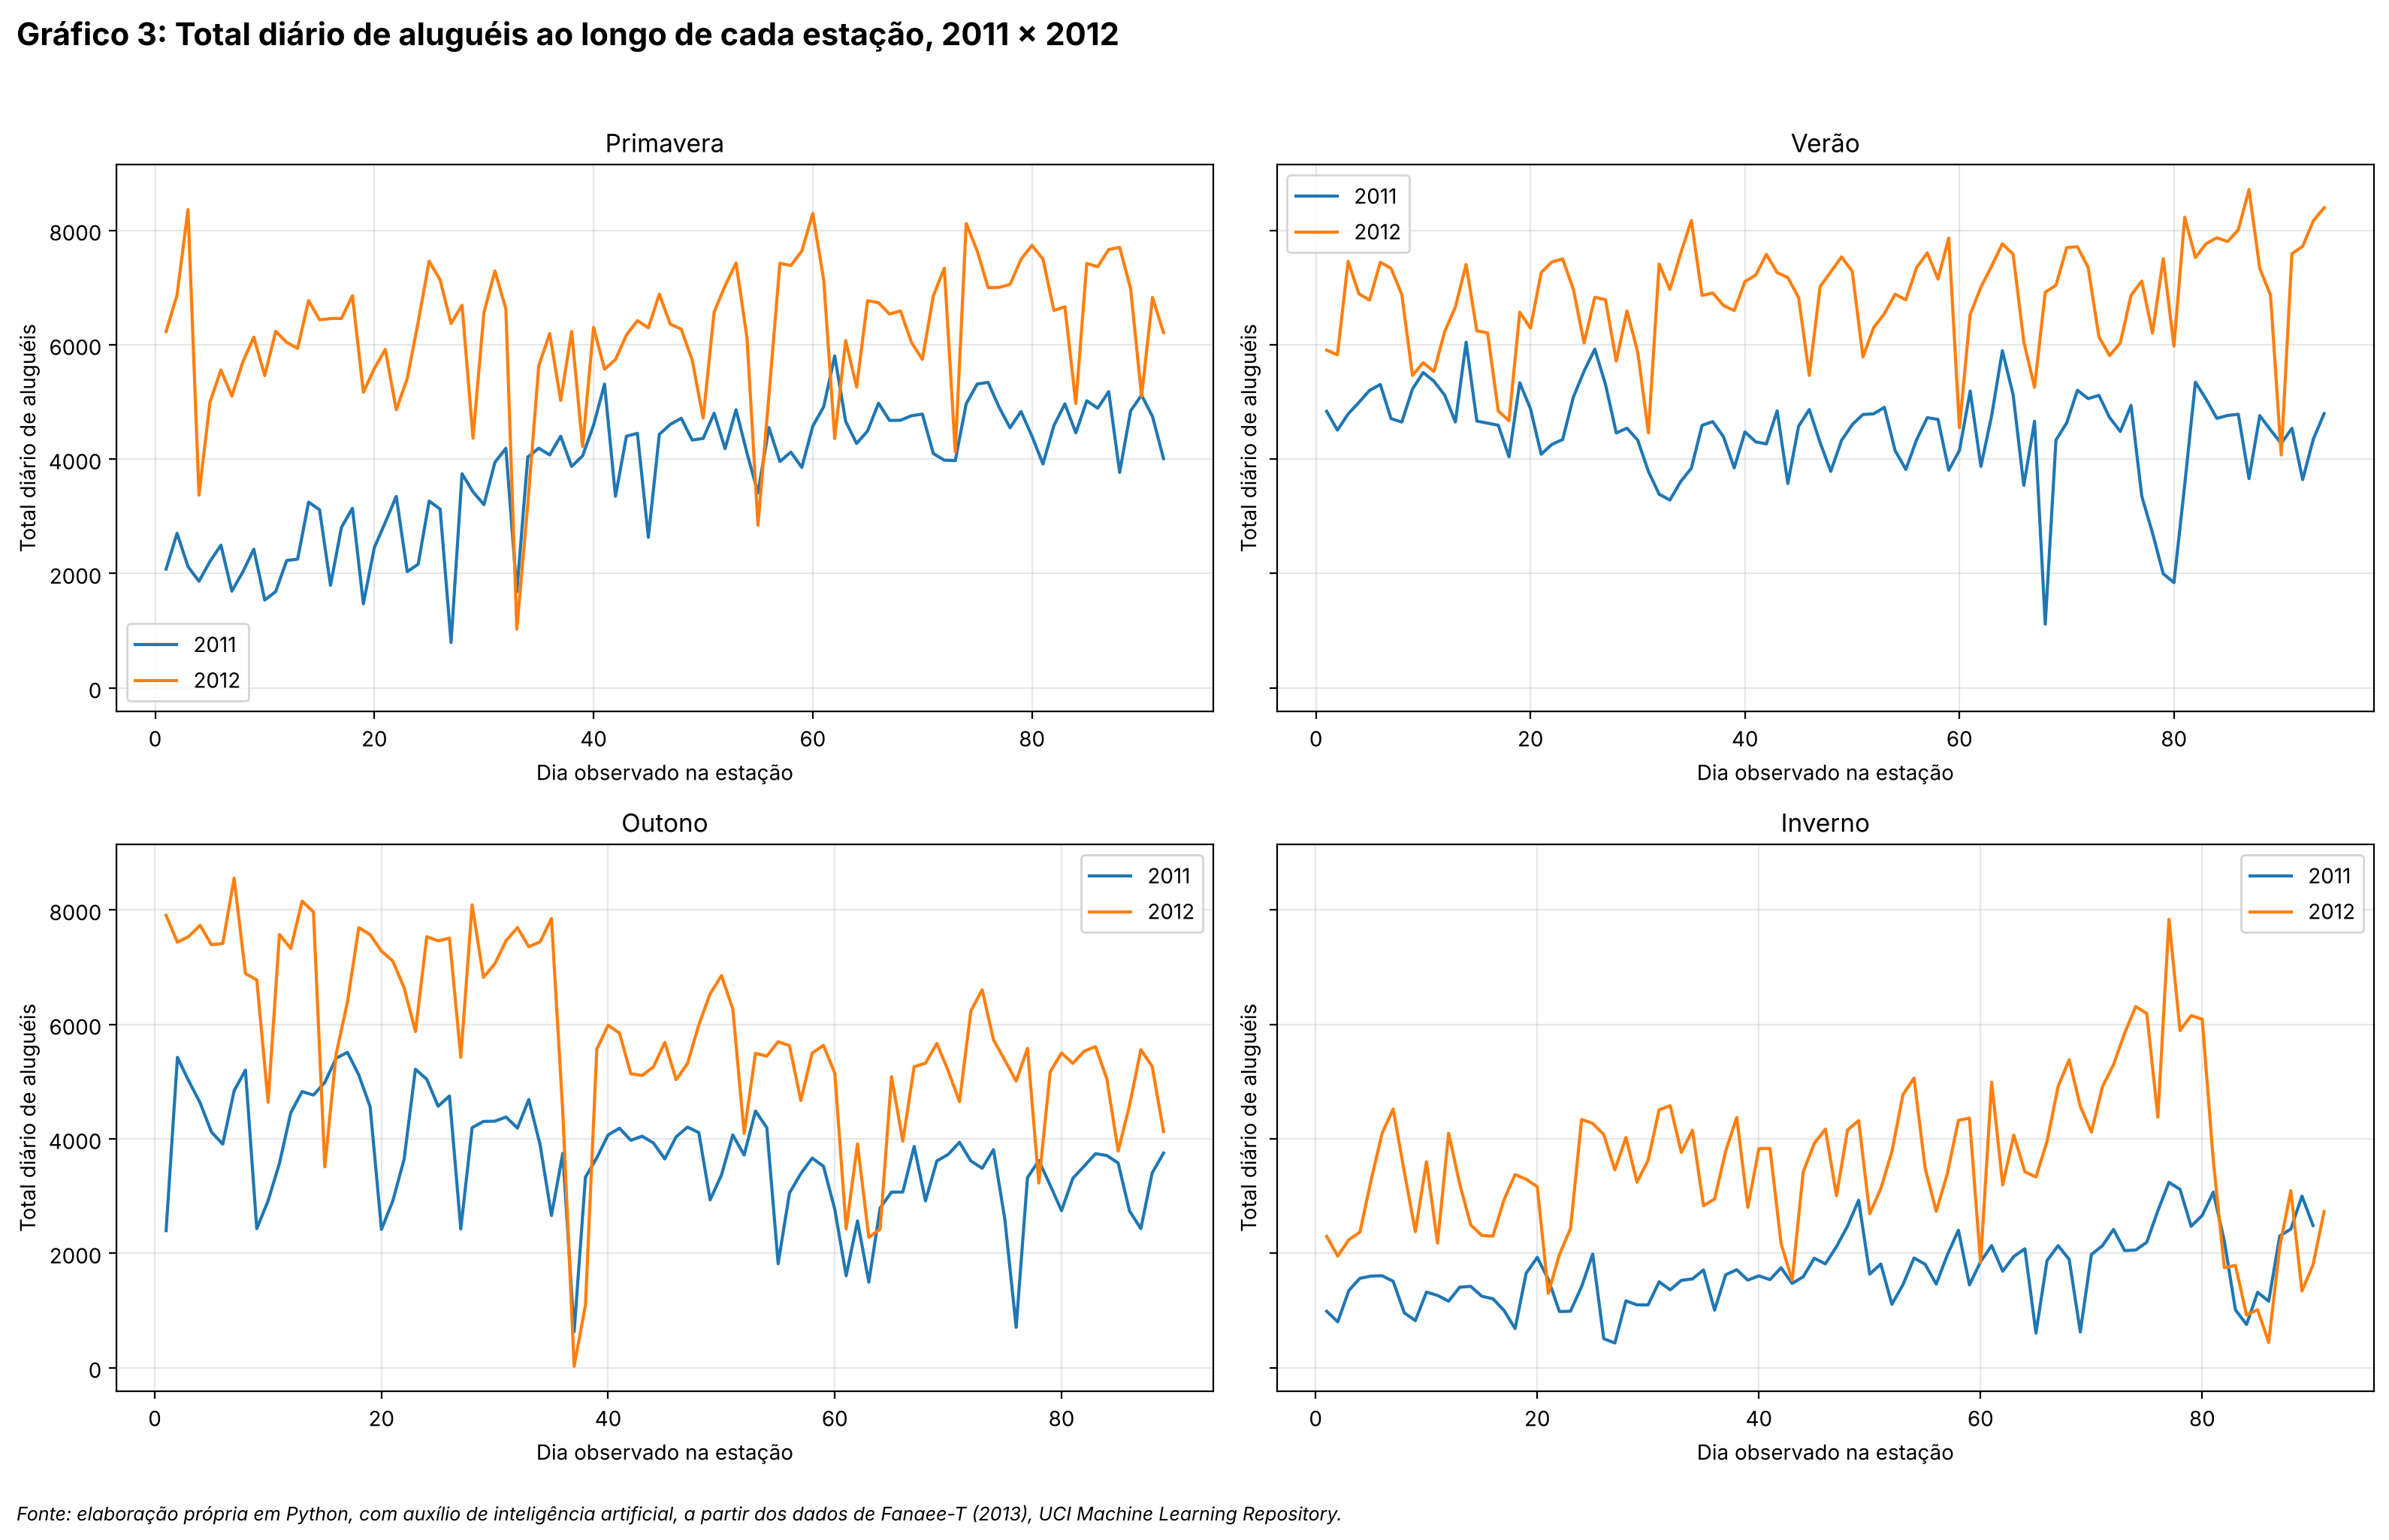

In [ ]:
# Analisando a demanda por estação, teremos:

# Número do gráfico no relatório
numero_grafico = 3

# Total de aluguéis em cada dia
diario = df.groupby(['dteday', 'season', 'yr'])['cnt'].sum().reset_index()

# Numerar os dias dentro de cada estação de cada ano: 1, 2, 3, ...
diario['dia_na_estacao'] = diario.groupby(['season', 'yr']).cumcount() + 1

nomes_estacao = {1: 'Inverno', 2: 'Primavera', 3: 'Verão', 4: 'Outono'}
nomes_ano = {0: '2011', 1: '2012'}
ordem = [2, 3, 4, 1]   # Primavera, Verão, Outono, Inverno

fig, eixos = plt.subplots(2, 2, figsize=(16, 10), sharey=True)

for eixo, estacao in zip(eixos.flatten(), ordem):
    dados = diario[diario['season'] == estacao]
    for ano in [0, 1]:
        d = dados[dados['yr'] == ano]
        eixo.plot(d['dia_na_estacao'], d['cnt'], label=nomes_ano[ano])
    eixo.set_title(nomes_estacao[estacao])
    eixo.set_xlabel('Dia observado na estação')
    eixo.set_ylabel('Total diário de aluguéis')
    eixo.grid(alpha=0.3)
    eixo.legend()

# Título geral da figura, acima dos quatro painéis
fig.suptitle(
    f'Gráfico {numero_grafico}: Total diário de aluguéis ao longo de cada estação, 2011 x 2012',
    fontsize=15, fontweight='bold', x=0.01, ha='left'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
nota_grafico()
plt.savefig(f'figuras/grafico_{numero_grafico}.png', dpi=300, bbox_inches='tight')
plt.show()

### Para termos um valor quantitativo, essas foram as médias de aluguel diário por estação:


In [ ]:
# Tabela de média:

# Número da tabela no relatório
numero_tabela = 2

# Total de aluguéis em cada dia
diario = df.groupby(['dteday', 'season', 'yr'])['cnt'].sum().reset_index()

# Média do total diário por estação e ano
tabela = diario.groupby(['season', 'yr'])['cnt'].mean().unstack()

# Nomes legíveis
tabela.index = tabela.index.map({1: 'Inverno', 2: 'Primavera', 3: 'Verão', 4: 'Outono'})
tabela.index.name = 'Estação'
tabela.columns = ['2011', '2012']

# Variação de 2011 para 2012
tabela['Variação (%)'] = (tabela['2012'] / tabela['2011'] - 1) * 100

# Exibir formatado, com título
# Exportar para o relatório
tabela.round(1).to_csv(f'tabelas/tabela_{numero_tabela}.csv')

tabela_exibida = tabela.style.format(
    {'2011': '{:,.0f}', '2012': '{:,.0f}', 'Variação (%)': '{:.0f}%'},
    thousands='.'
).set_caption(
    f'Tabela {numero_tabela}: Média do total diário de aluguéis por estação e ano '
    '(2011–2012), com variação percentual entre os anos.'
).set_table_styles([
    {'selector': 'caption',
     'props': [('font-weight', 'bold'), ('text-align', 'left')]},
    {'selector': 'th',
     'props': [('text-align', 'center')]}
])

display(tabela_exibida)
display(Markdown(f'*{FONTE}*'))


,2011,2012,Variação (%)
Estação,,,
Inverno,1.667,3.531,112%
Primavera,3.775,6.209,64%
Verão,4.464,6.824,53%
Outono,3.664,5.792,58%


*Fonte: elaboração própria em Python, com auxílio de inteligência artificial, a partir dos dados de Fanaee-T (2013), UCI Machine Learning Repository.*

In [ ]:
### Conclusão da Análise 2

### A demanda varia com a estação: é mais baixa no inverno e mais alta no verão, com primavera e outono em posição intermediária.
### Esse padrão se repete em 2011 e 2012, sempre com 2012 acima de 2011. Também aparecem quedas pontuais ligadas a eventos, como o furacão Sandy
### no outono de 2012, quando o serviço foi suspenso e quase não há registros. Portanto, 'season' deve ser uma variável importante para prever 'cnt'.

# ---- MOTIVAÇÃO PARA ANÁLISE 3: DIAS QUENTES POSSUEM MAIS ALUGUÉIS? ----

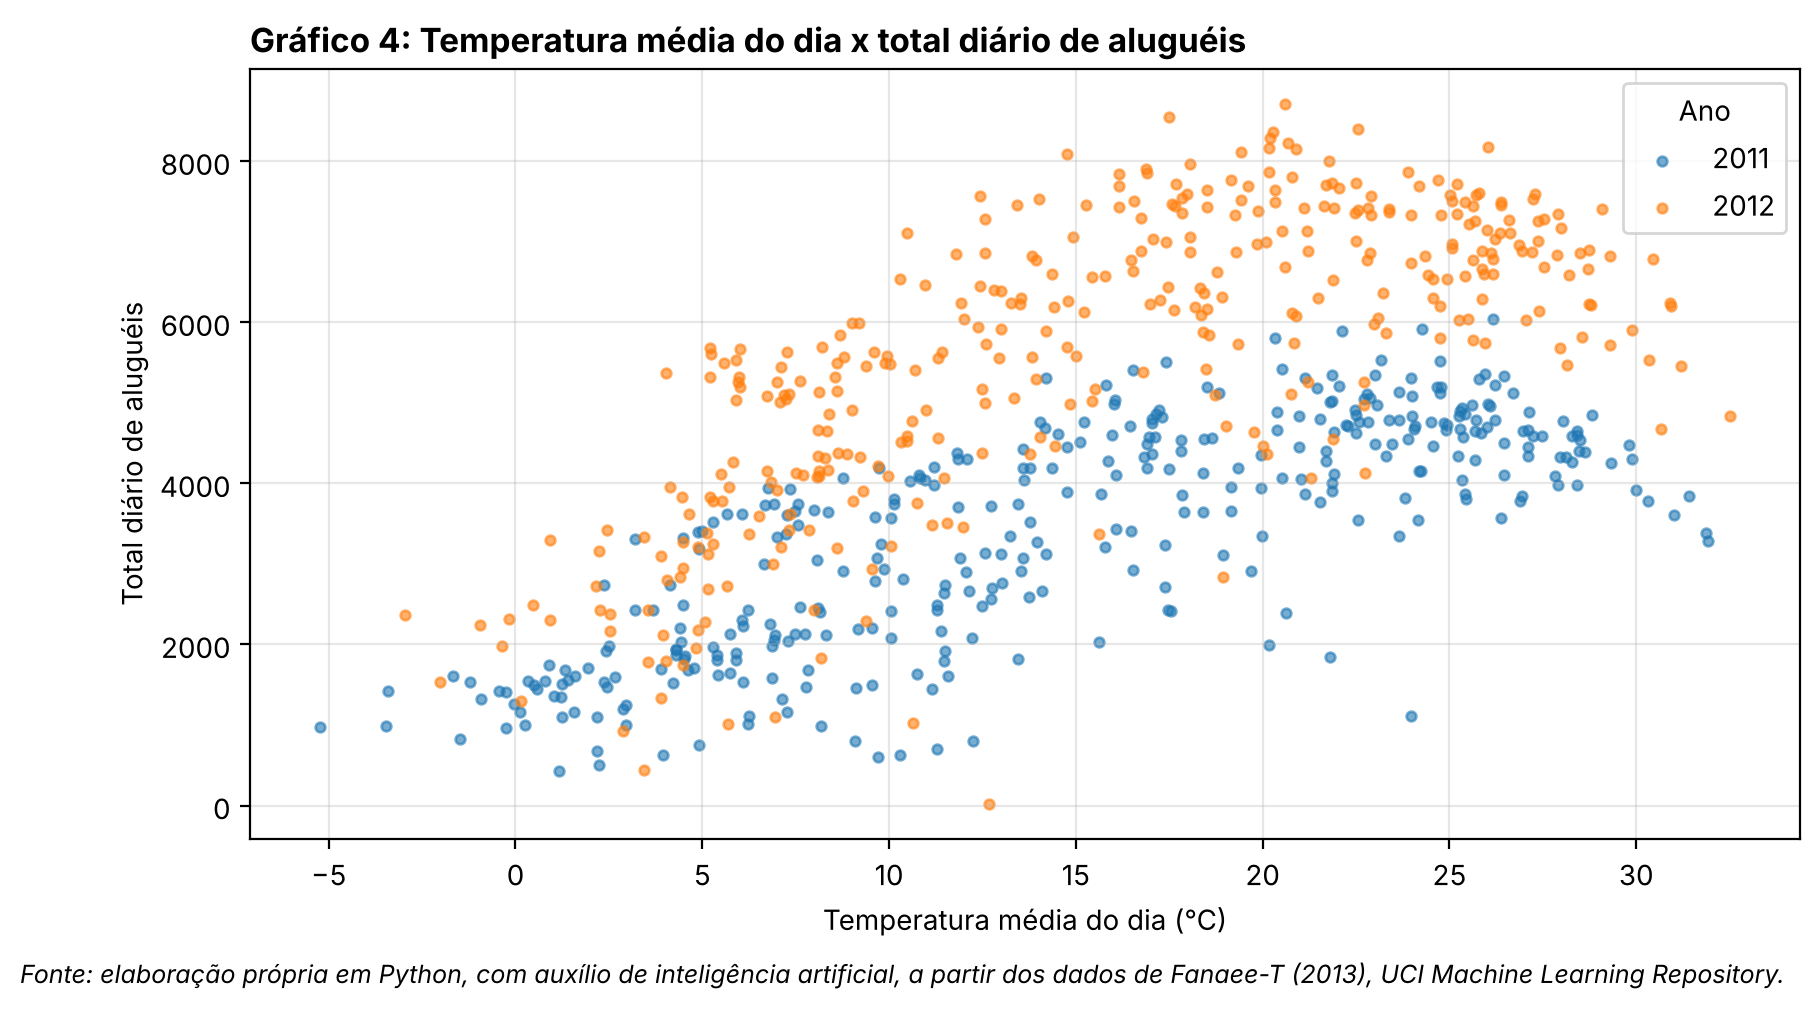

In [ ]:
# Número do gráfico no relatório
numero_grafico = 4

# Temperatura em °C
df['temp_c'] = df['temp'] * 47 - 8

# Para cada dia: total de aluguéis e temperatura média
dia = df.groupby(['dteday', 'yr']).agg(
    cnt=('cnt', 'sum'),
    temp_c=('temp_c', 'mean')
).reset_index()

plt.figure(figsize=(10, 5))
for ano, nome in [(0, '2011'), (1, '2012')]:
    d = dia[dia['yr'] == ano]
    plt.scatter(d['temp_c'], d['cnt'], s=12, alpha=0.6, label=nome)

plt.title(
    f'Gráfico {numero_grafico}: Temperatura média do dia x total diário de aluguéis',
    fontweight='bold', loc='left'
)
plt.xlabel('Temperatura média do dia (°C)')
plt.ylabel('Total diário de aluguéis')
plt.legend(title='Ano')
plt.grid(alpha=0.3)
nota_grafico()
plt.savefig(f'figuras/grafico_{numero_grafico}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Número da tabela no relatório
numero_tabela = 3

# Temperatura em °C
df['temp_c'] = df['temp'] * 47 - 8

# Para cada dia: total de aluguéis e temperatura média
dia = df.groupby(['dteday', 'yr']).agg(
    cnt=('cnt', 'sum'),
    temp_c=('temp_c', 'mean')
).reset_index()

# Separar os dias em faixas de 5 °C
faixas = [-10, -5, 0, 5, 10, 15, 20, 25, 30, 35]
rotulos = ['−10 a −5 °C', '−5 a 0 °C', '0 a 5 °C', '5 a 10 °C', '10 a 15 °C',
           '15 a 20 °C', '20 a 25 °C', '25 a 30 °C', '30 a 35 °C']
dia['faixa_temp'] = pd.cut(dia['temp_c'], bins=faixas, labels=rotulos)

# Média do total diário por faixa e ano
tabela_temp = dia.groupby(['faixa_temp', 'yr'], observed=True)['cnt'].mean().unstack()
tabela_temp.columns = ['Média diária 2011', 'Média diária 2012']
tabela_temp.index.name = 'Temperatura média do dia'

# Quantos dias caem em cada faixa
tabela_temp['Nº de dias'] = dia.groupby('faixa_temp', observed=True).size()

# Exibir formatado, com título
# Exportar para o relatório
tabela_temp.round(1).to_csv(f'tabelas/tabela_{numero_tabela}.csv')

tabela_exibida = tabela_temp.style.format(
    {'Média diária 2011': '{:,.0f}', 'Média diária 2012': '{:,.0f}', 'Nº de dias': '{:.0f}'},
    thousands='.', na_rep='–'
).set_caption(
    f'Tabela {numero_tabela}: Média do total diário de aluguéis por faixa de temperatura e ano (2011–2012).'
)

display(tabela_exibida)
display(Markdown(f'*{FONTE}*'))


,Média diária 2011,Média diária 2012,Nº de dias
Temperatura média do dia,,,
−10 a −5 °C,981,–,1
−5 a 0 °C,1.274,2.084,15
0 a 5 °C,1.707,2.602,81
5 a 10 °C,2.498,4.334,143
10 a 15 °C,3.157,5.482,120
15 a 20 °C,4.133,6.666,110
20 a 25 °C,4.562,6.836,134
25 a 30 °C,4.558,6.850,115
30 a 35 °C,3.582,5.677,12


*Fonte: elaboração própria em Python, com auxílio de inteligência artificial, a partir dos dados de Fanaee-T (2013), UCI Machine Learning Repository.*

In [ ]:
## Na coluna de 2012, a faixa de −10 a −5 °C ficou vazia: em 2012, nenhum dia teve temperatura média abaixo de −5 °C.
## A queda acima de 30 °C se baseia em apenas 12 dias, o que pede cautela na interpretação.
## A demanda sobe com a temperatura até cerca de 20 a 30 °C, fica estável nessa faixa e cai acima de 30 °C.
## Ou seja, existe uma temperatura ideal para pedalar: nem muito frio e nem muito quente.

In [ ]:
### Conclusão da Análise 3

### A demanda cresce com a temperatura até uma faixa de conforto, entre aproximadamente 20 e 30 °C,
### e diminui nos dias mais quentes, acima de 30 °C. O padrão se repete nos dois anos, com 2012 sempre acima de 2011.
### A relação entre temperatura e demanda não é linear, o que favorece modelos baseados em árvores,
### capazes de capturar efeitos diferentes em cada faixa de temperatura. Portanto, 'temp' deve ser uma variável importante para prever 'cnt'.

#--------------- MOTIVAÇÃO PARA ANÁLISE 4: o padrão de uso das bicicletas é diferente em dias úteis e em fins de semana? ---------------------

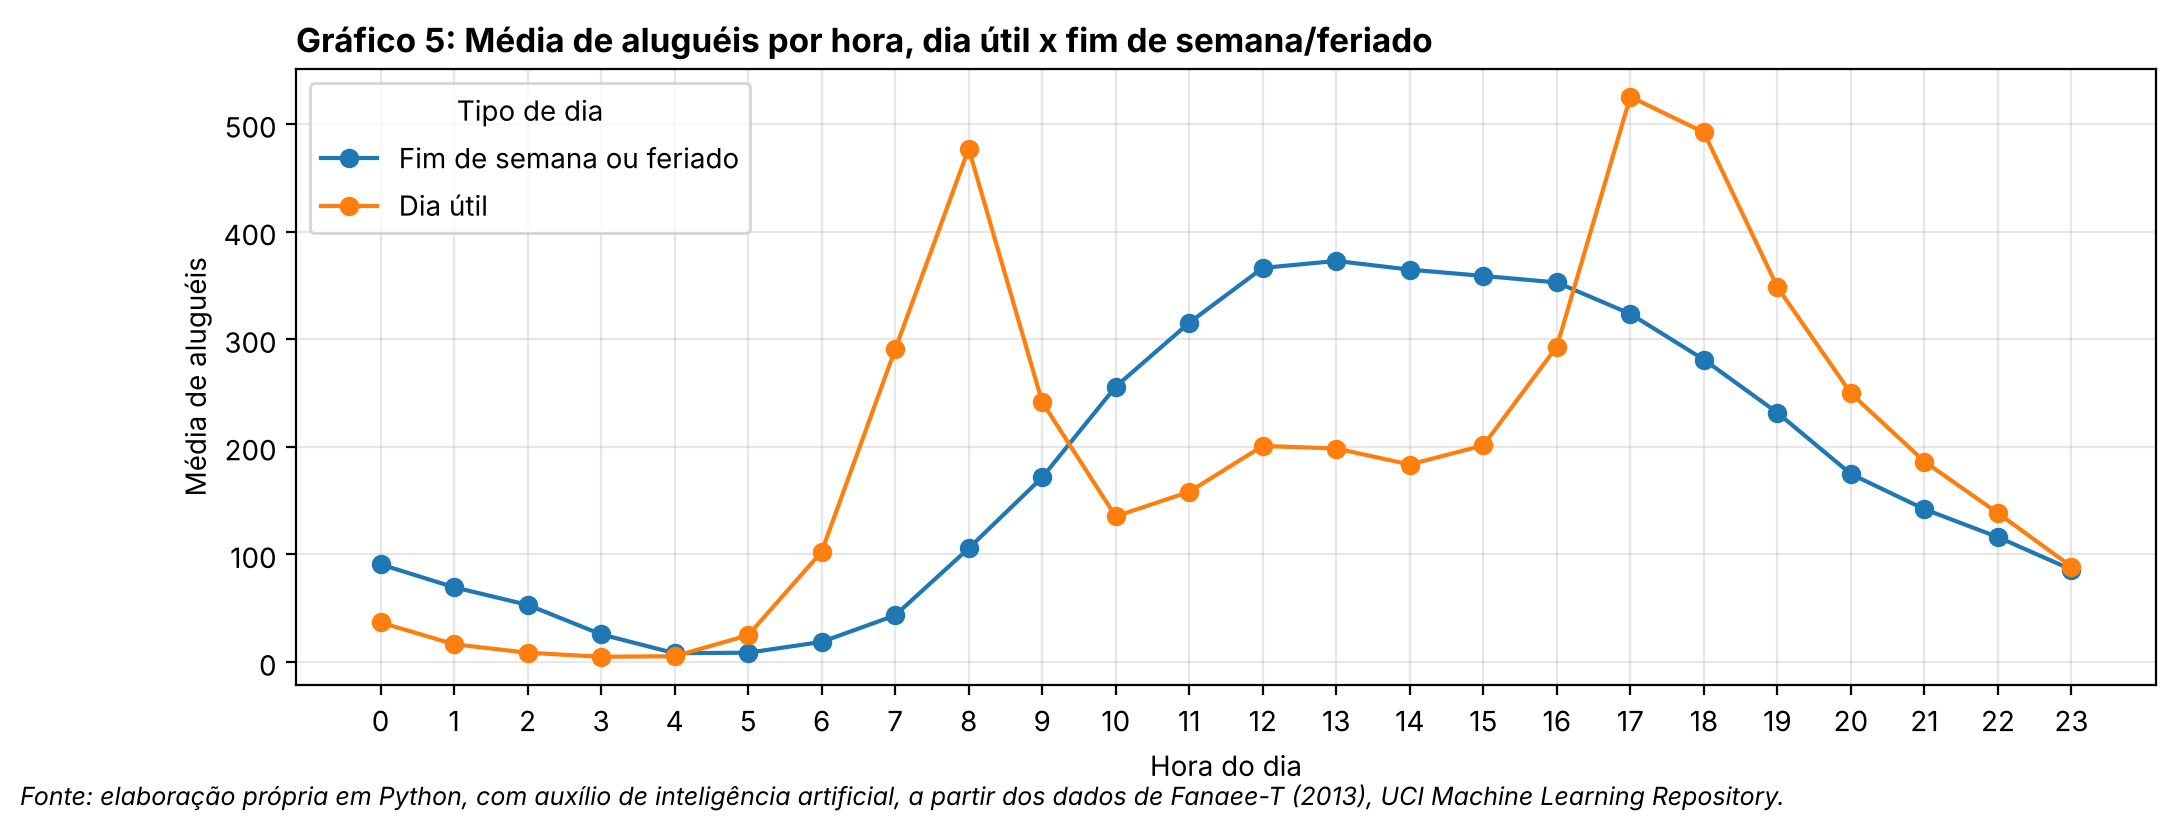

In [ ]:
# Número do gráfico no relatório
numero_grafico = 5

media_hora_tipo = df.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
media_hora_tipo.columns = ['Fim de semana ou feriado', 'Dia útil']

media_hora_tipo.plot(figsize=(12, 4), marker='o')
plt.title(
    f'Gráfico {numero_grafico}: Média de aluguéis por hora, dia útil x fim de semana/feriado',
    fontweight='bold', loc='left'
)
plt.xlabel('Hora do dia')
plt.ylabel('Média de aluguéis')
plt.xticks(range(24))
plt.legend(title='Tipo de dia')
plt.grid(alpha=0.3)
nota_grafico()
plt.savefig(f'figuras/grafico_{numero_grafico}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Média de aluguéis por hora, separada por tipo de dia
media_hora_tipo = df.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
media_hora_tipo.columns = ['Fim de semana ou feriado', 'Dia útil']

util = media_hora_tipo['Dia útil']
fds = media_hora_tipo['Fim de semana ou feriado']

# 1. Picos
pico_manha = util.loc[0:11].idxmax()     # hora de maior média entre 0h e 11h
pico_tarde = util.loc[12:23].idxmax()    # hora de maior média entre 12h e 23h
pico_fds = fds.idxmax()                  # hora de maior média no fim de semana

print('PICOS')
print(f'Dia útil, manhã: {pico_manha}h ({util[pico_manha]:.0f} aluguéis em média)')
print(f'Dia útil, tarde: {pico_tarde}h ({util[pico_tarde]:.0f} aluguéis em média)')
print(f'Fim de semana/feriado: {pico_fds}h ({fds[pico_fds]:.0f} aluguéis em média)')

# Platô do fim de semana: horas com pelo menos 85% do valor do pico
plato = fds[fds >= 0.85 * fds.max()].index
print(f'Platô do fim de semana (>= 85% do pico): {plato.min()}h a {plato.max()}h')

# 2. Total diário médio por tipo de dia
total_dia = df.groupby(['dteday', 'workingday'])['cnt'].sum().reset_index()
media_total = total_dia.groupby('workingday')['cnt'].mean()

print('\nTOTAL DIÁRIO MÉDIO')
print(f'Dia útil: {media_total[1]:,.0f}'.replace(',', '.'))
print(f'Fim de semana/feriado: {media_total[0]:,.0f}'.replace(',', '.'))
print(f'Diferença: {(media_total[1] / media_total[0] - 1) * 100:.1f}%')

# 3. Madrugada
print('\nMEIA-NOITE (hr = 0)')
print(f'Dia útil: {util[0]:.0f}  |  Fim de semana/feriado: {fds[0]:.0f}')
print(f'O fim de semana tem {fds[0] / util[0]:.1f} vezes mais aluguéis à meia-noite')

PICOS
Dia útil, manhã: 8h (477 aluguéis em média)
Dia útil, tarde: 17h (525 aluguéis em média)
Fim de semana/feriado: 13h (373 aluguéis em média)
Platô do fim de semana (>= 85% do pico): 12h a 17h

TOTAL DIÁRIO MÉDIO
Dia útil: 4.585
Fim de semana/feriado: 4.330
Diferença: 5.9%

MEIA-NOITE (hr = 0)
Dia útil: 37  |  Fim de semana/feriado: 91
O fim de semana tem 2.5 vezes mais aluguéis à meia-noite


In [ ]:
### Conclusão da Análise 4

### O padrão horário da demanda muda conforme o tipo de dia. Em dias úteis, há dois picos, por volta das 8h e das 17h–18h,
### compatíveis com o deslocamento casa–trabalho. Em fins de semana e feriados, a demanda se concentra entre 12h e 17h,
### com pico por volta das 13h, sugerindo uso para lazer e passeio.
### O total diário de aluguéis é semelhante nos dois tipos de dia (cerca de 4.585 contra 4.330); o que muda é a distribuição ao longo das horas.
### Como o efeito da hora depende do tipo de dia, 'hr' e 'workingday' devem ser usadas em conjunto,
### e modelos baseados em árvores conseguem capturar essa interação.

# UM BREVE FECHAMENTO

In [ ]:
### Conclusão sobre as 4 análises (principais fatores que encontramos tratando os dados)

# 1. A hora do dia é o fator que mais muda a demanda, com picos ligados ao deslocamento casa–trabalho.
# 2. A demanda cresceu cerca de 63% de 2011 para 2012, em todas as horas e estações.
# 3. A demanda é menor no inverno e maior no verão.
# 4. A demanda cresce com a temperatura até cerca de 20–30 °C e cai nos dias mais quentes.
# 5. Dias úteis e fins de semana têm padrões horários diferentes, mas totais diários parecidos.

# Portanto, espera-se que 'hr', 'yr', 'temp', 'season' e 'workingday' estejam entre as variáveis mais importantes.

# INICIO DA MODELAGEM

In [ ]:
# Colunas que o modelo pode usar como entrada
colunas_entrada = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
                   'workingday', 'weathersit', 'temp', 'hum', 'windspeed']

X = df_modelo[colunas_entrada]
y = df_modelo['cnt']

print('Formato de X:', X.shape)
print('Formato de y:', y.shape)

# Por que excluímos as outras colunas?

# cnt -> é a resposta (y)
# casual e registered -> somadas dão o cnt; usá-las seria vazamento de dados
# atemp -> repete a informação de temp e tem erro de registro em 17/08/2012
# instant -> apenas a numeração das linhas
# dteday -> a informação da data já está em yr, mnth, weekday e holiday


Formato de X: (17379, 11)
Formato de y: (17379,)


In [ ]:
## Utilizaremos todo o dataset até setembro de 2012 para treinar o modelo, e testaremos com outubro a dezembro de 2012.

In [ ]:
corte = '2012-10-01'
eh_treino = df_modelo['dteday'] < corte

X_treino = X[eh_treino]
X_teste = X[~eh_treino]
y_treino = y[eh_treino]
y_teste = y[~eh_treino]

print('Treino:', X_treino.shape, '| de', df_modelo.loc[eh_treino, 'dteday'].min().date(),
      'até', df_modelo.loc[eh_treino, 'dteday'].max().date())
print('Teste: ', X_teste.shape, '| de', df_modelo.loc[~eh_treino, 'dteday'].min().date(),
      'até', df_modelo.loc[~eh_treino, 'dteday'].max().date())

Treino: (15211, 11) | de 2011-01-01 até 2012-09-30
Teste:  (2168, 11) | de 2012-10-01 até 2012-12-31


In [ ]:
# A divisão entre treino e teste foi feita por data, para respeitar a ordem temporal dos dados.
# O treino cobre de janeiro de 2011 a setembro de 2012 (cerca de 21 meses, 87,5% das observações) e o teste cobre o último trimestre de 2012 (cerca de 3 meses, 12,5%).
# A escolha de um trimestre completo simula o uso prático do modelo, que é prever a demanda futura a partir do histórico, e o período inclui situações desafiadoras,
# como o furacão Sandy, o Natal e o início do inverno.

In [ ]:
# Usaremos aqui três métricas: Erro absoluto médio (MAE), Raiz do erro quadrático médio (RMSE) e
# o coeficiente de determinação (R²).

In [ ]:
# Como vimos na análise 4: Para prever uma hora, use a média de aluguéis daquela mesma hora,
# no mesmo tipo de dia (útil ou fim de semana), calculada no treino. Então:

MAE:  80.0
RMSE: 119.6
R²:   0.648


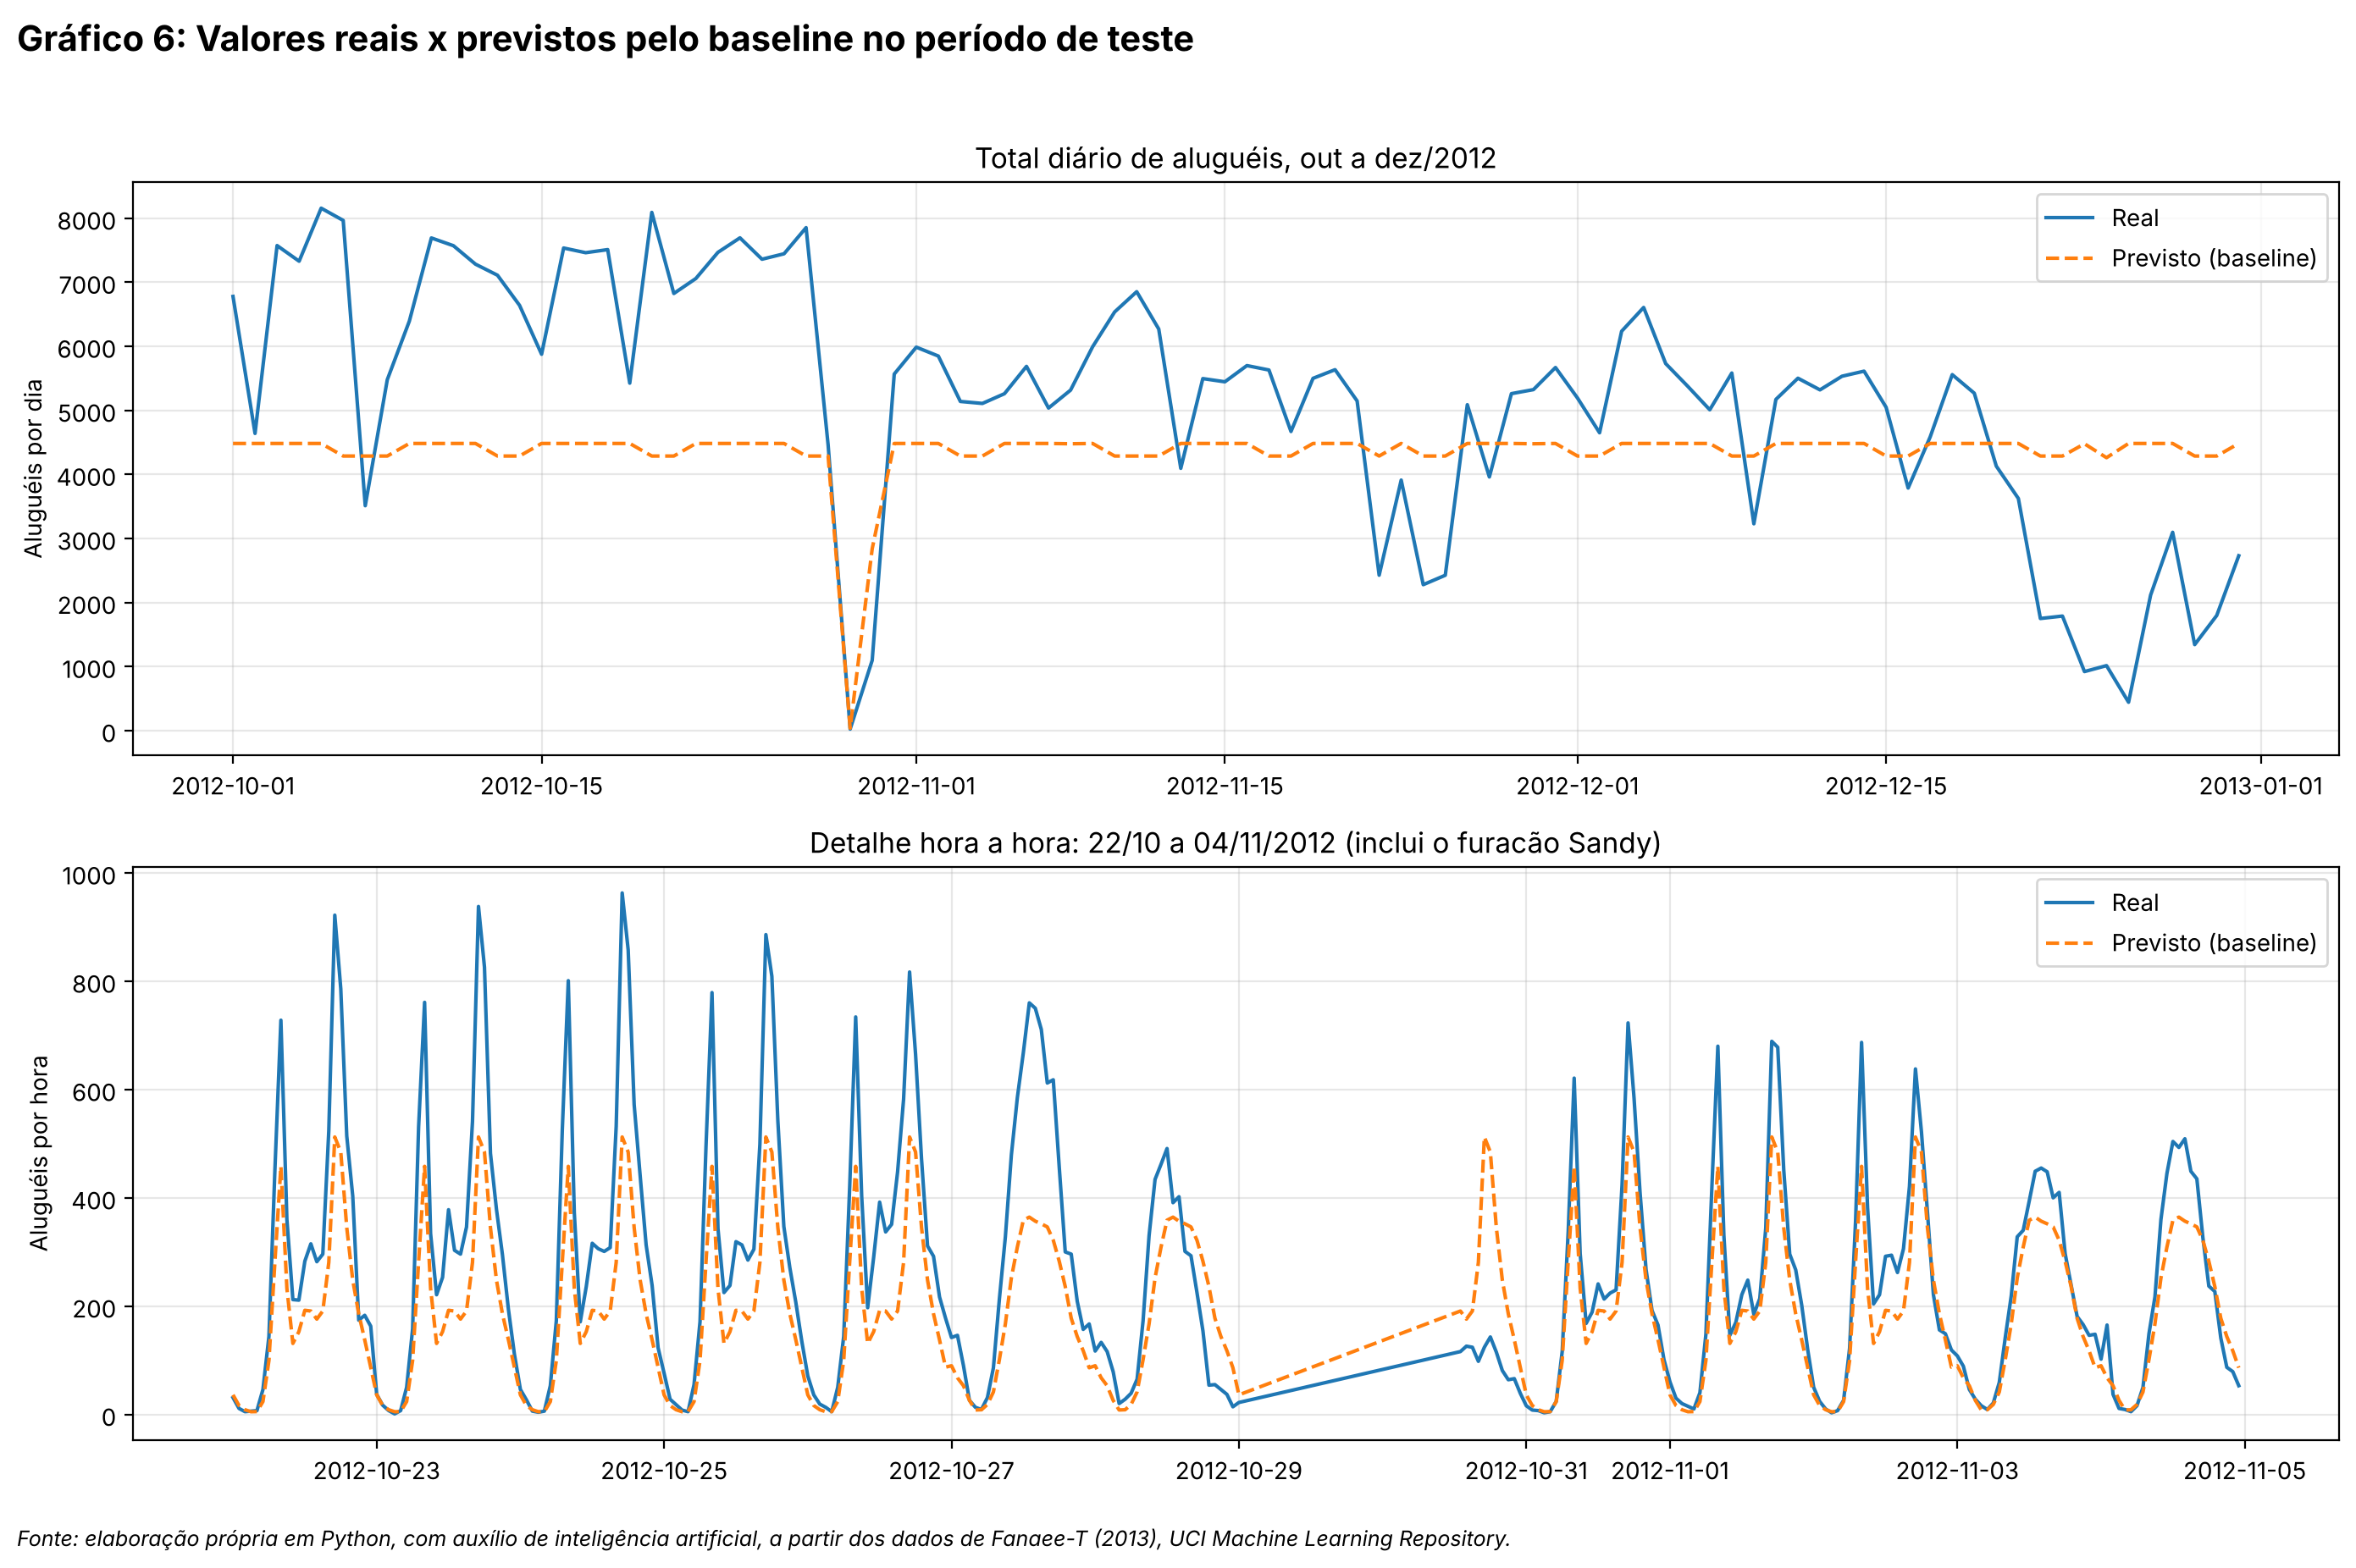

In [ ]:
# Média do treino para cada combinação de hora e tipo de dia
media_treino = y_treino.groupby([X_treino['hr'], X_treino['workingday']]).mean()
media_treino.name = 'previsao'

# Para cada hora do teste, buscar a média correspondente
prev_baseline = X_teste.join(media_treino, on=['hr', 'workingday'])['previsao']

# Medir o erro
mae = mean_absolute_error(y_teste, prev_baseline)
rmse = np.sqrt(mean_squared_error(y_teste, prev_baseline))
r2 = r2_score(y_teste, prev_baseline)

print(f'MAE:  {mae:.1f}')
print(f'RMSE: {rmse:.1f}')
print(f'R²:   {r2:.3f}')

# Número do gráfico no relatório
numero_grafico = 6

# Juntar data e hora, valor real e previsão numa tabela só
resultado = pd.DataFrame({
    'datahora': df_modelo.loc[~eh_treino, 'dteday'] + pd.to_timedelta(df_modelo.loc[~eh_treino, 'hr'], unit='h'),
    'real': y_teste,
    'previsto': prev_baseline
})

# Painel de cima: total por dia
por_dia = resultado.groupby(resultado['datahora'].dt.date)[['real', 'previsto']].sum()

# Painel de baixo: só as duas semanas do furacão Sandy
semanas = resultado[(resultado['datahora'] >= '2012-10-22') & (resultado['datahora'] < '2012-11-05')]

fig, eixos = plt.subplots(2, 1, figsize=(14, 9))

eixos[0].plot(por_dia.index, por_dia['real'], label='Real')
eixos[0].plot(por_dia.index, por_dia['previsto'], label='Previsto (baseline)', linestyle='--')
eixos[0].set_title('Total diário de aluguéis, out a dez/2012')
eixos[0].set_ylabel('Aluguéis por dia')
eixos[0].legend()
eixos[0].grid(alpha=0.3)

eixos[1].plot(semanas['datahora'], semanas['real'], label='Real')
eixos[1].plot(semanas['datahora'], semanas['previsto'], label='Previsto (baseline)', linestyle='--')
eixos[1].set_title('Detalhe hora a hora: 22/10 a 04/11/2012 (inclui o furacão Sandy)')
eixos[1].set_ylabel('Aluguéis por hora')
eixos[1].legend()
eixos[1].grid(alpha=0.3)

fig.suptitle(f'Gráfico {numero_grafico}: Valores reais x previstos pelo baseline no período de teste',
             fontsize=15, fontweight='bold', x=0.01, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.96])
nota_grafico()
plt.savefig(f'figuras/grafico_{numero_grafico}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
## Em média, essa regra erra por 80 bicicletas por hora (MAE).

## R² = 0,648. A regra explica cerca de 65% da variação da demanda. É bem melhor que chutar sempre a média (que daria R² = 0),
## mas sobram 35% sem explicação.

## Não se sabe o clima, a temperatura, a estação nem o ano. E a Análise 1 mostrou que 2012 tem muito mais demanda que 2011,
## mas a regra mistura os dois anos, e por isso tende a subestimar o fim de 2012.

In [ ]:
# Resultado do baseline:

# O modelo de referência, que prevê a média de aluguéis da mesma hora e do mesmo tipo de dia no período de treino, obteve MAE de 80,0,
# RMSE de 119,6 e R² de 0,648. Os modelos de aprendizado de máquina devem superar esses valores para justificar seu uso.

In [ ]:
# Criando a primeira árvore de decisão:

# Criar e treinar a árvore
arvore_livre = DecisionTreeRegressor(random_state=42)
arvore_livre.fit(X_treino, y_treino)

# Avaliar no treino e no teste
for nome, X_parte, y_parte in [('Treino', X_treino, y_treino), ('Teste', X_teste, y_teste)]:
    prev = arvore_livre.predict(X_parte)
    mae = mean_absolute_error(y_parte, prev)
    rmse = np.sqrt(mean_squared_error(y_parte, prev))
    r2 = r2_score(y_parte, prev)
    print(f'{nome}: MAE = {mae:.1f} | RMSE = {rmse:.1f} | R² = {r2:.3f}')

print('Profundidade da árvore:', arvore_livre.get_depth())
print('Número de folhas:', arvore_livre.get_n_leaves())

Treino: MAE = 0.0 | RMSE = 0.5 | R² = 1.000
Teste: MAE = 56.8 | RMSE = 88.1 | R² = 0.809
Profundidade da árvore: 30
Número de folhas: 14428


In [ ]:
# como de um lado tivemos MAE = 0 e do outro tivemos MAE aproximadamente igual a 57, isso é um sinal de overfitting, alguma diferença entre treino e teste é normal,
# mas uma distância tão grande indica que a árvore decorou os dados de treino em vez de aprender regras gerais.
# Podemos corrigir isso limitando o crescimento da árvore para forçá-la a aprender regras mais gerais.

Profundidade    2: MAE treino =  85.5 | MAE validação = 128.1
Profundidade    4: MAE treino =  72.8 | MAE validação = 110.8
Profundidade    6: MAE treino =  57.3 | MAE validação =  90.0
Profundidade    8: MAE treino =  39.3 | MAE validação =  59.5
Profundidade   10: MAE treino =  28.7 | MAE validação =  50.5
Profundidade   12: MAE treino =  19.2 | MAE validação =  52.3


Profundidade   15: MAE treino =   8.9 | MAE validação =  51.7


Profundidade   20: MAE treino =   1.6 | MAE validação =  51.0
Profundidade None: MAE treino =   0.0 | MAE validação =  51.4


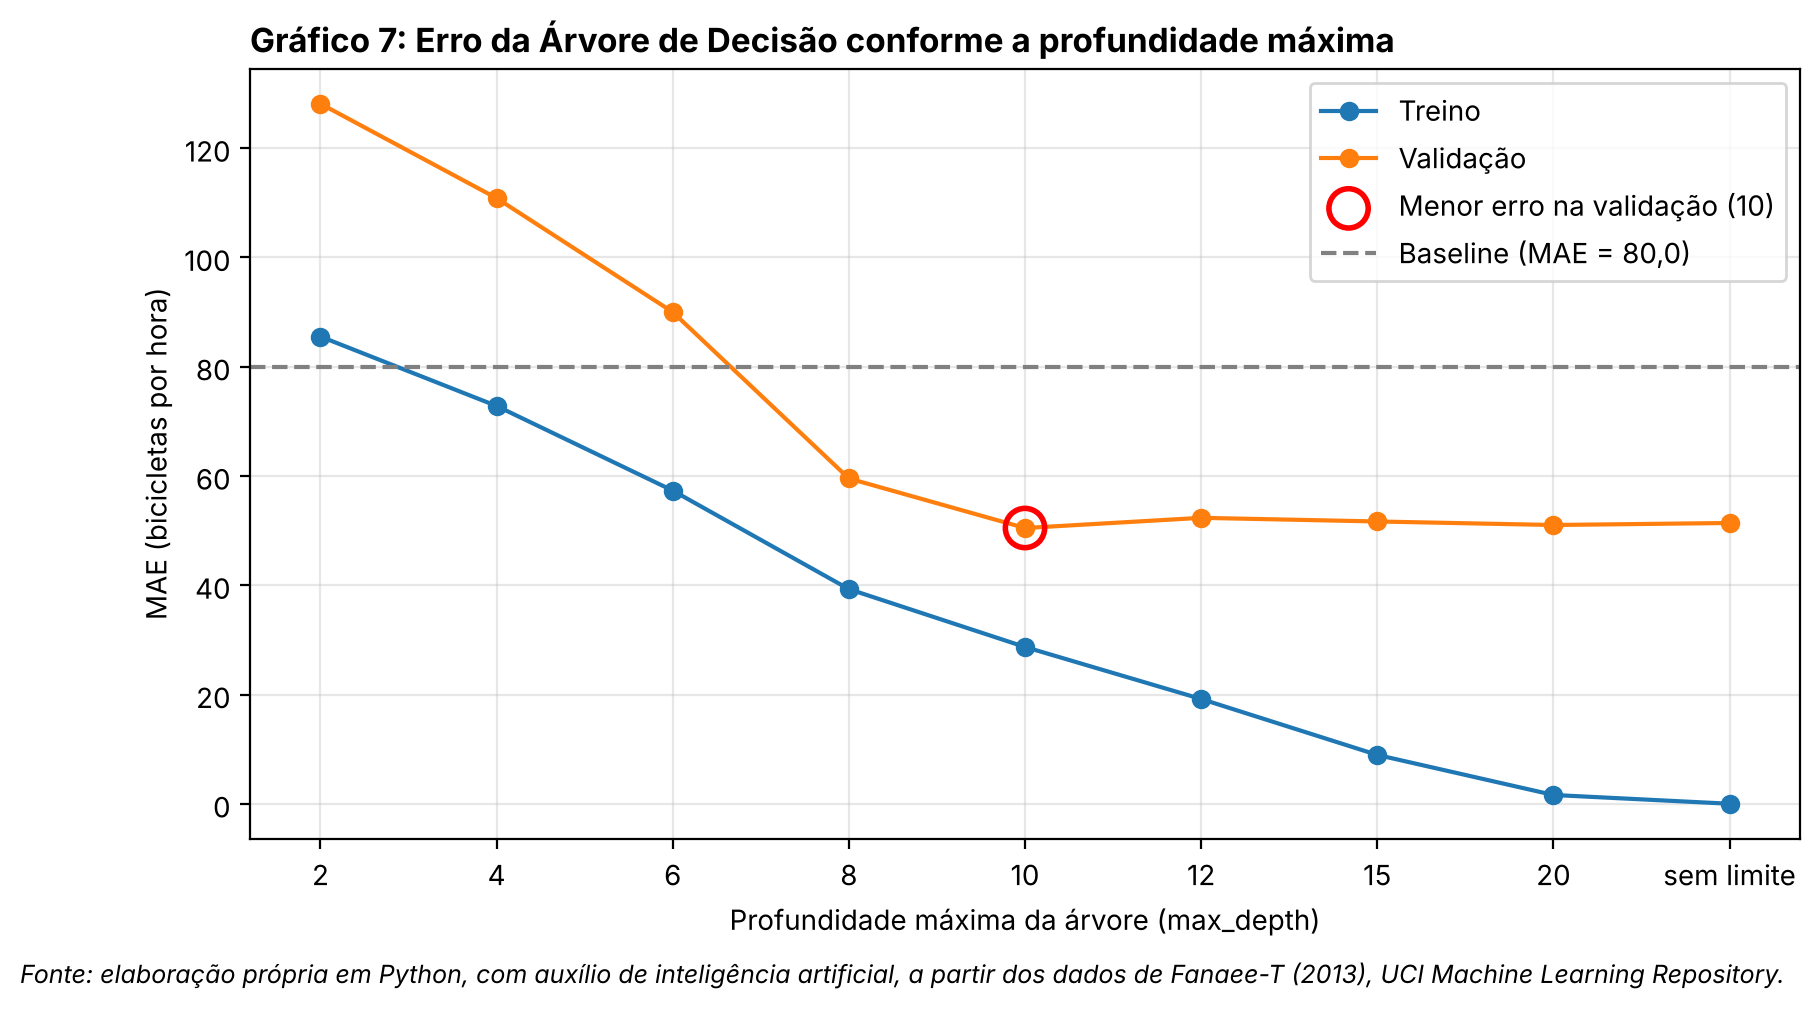

In [ ]:
# número do gráfico no relatório
numero_grafico = 7

# separar a validação: os últimos 3 meses do treino (jul a set/2012)
datas_treino = df_modelo.loc[eh_treino, 'dteday']
eh_validacao = datas_treino >= '2012-07-01'

X_tr, X_val = X_treino[~eh_validacao], X_treino[eh_validacao]
y_tr, y_val = y_treino[~eh_validacao], y_treino[eh_validacao]

# testar algumas profundidades e guardar os erros
profundidades = [2, 4, 6, 8, 10, 12, 15, 20, None]
erros_treino = []
erros_validacao = []

for profundidade in profundidades:
    arvore = DecisionTreeRegressor(max_depth=profundidade, random_state=42)
    arvore.fit(X_tr, y_tr)
    mae_tr = mean_absolute_error(y_tr, arvore.predict(X_tr))
    mae_val = mean_absolute_error(y_val, arvore.predict(X_val))
    erros_treino.append(mae_tr)
    erros_validacao.append(mae_val)
    print(f'Profundidade {str(profundidade):>4}: MAE treino = {mae_tr:5.1f} | MAE validação = {mae_val:5.1f}')

# gráfico: erro x profundidade
rotulos = [str(p) if p is not None else 'sem limite' for p in profundidades]
melhor = int(np.argmin(erros_validacao))

plt.figure(figsize=(10, 5))
plt.plot(rotulos, erros_treino, marker='o', label='Treino')
plt.plot(rotulos, erros_validacao, marker='o', label='Validação')
plt.scatter(rotulos[melhor], erros_validacao[melhor], s=200, facecolors='none',
            edgecolors='red', linewidths=2, zorder=5,
            label=f'Menor erro na validação ({rotulos[melhor]})')
plt.axhline(80.0, color='gray', linestyle='--', label='Baseline (MAE = 80,0)')
plt.title(f'Gráfico {numero_grafico}: Erro da Árvore de Decisão conforme a profundidade máxima',
          fontweight='bold', loc='left')
plt.xlabel('Profundidade máxima da árvore (max_depth)')
plt.ylabel('MAE (bicicletas por hora)')
plt.legend()
plt.grid(alpha=0.3)
nota_grafico()
plt.savefig(f'figuras/grafico_{numero_grafico}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
## Escolha da profundidade:

## A profundidade máxima foi escolhida por validação temporal (julho a setembro de 2012). O erro na validação cai até a profundidade 10 (MAE = 50,5) e se
## estabiliza a partir daí, enquanto o erro no treino continua caindo até zero, sinal de sobreajuste. Foi escolhida a profundidade 10, por ter o menor erro
## na validação e ser a mais simples entre as de desempenho equivalente.

In [ ]:
## Agora, vamos treinar de novo com o treino completo (jan/2011 a set/2012). A validação já cumpriu seu papel de ajudar a escolher,
## e agora esses 3 meses voltam para o treino, porque mais dados ajudam o modelo.

In [ ]:
arvore_final = DecisionTreeRegressor(max_depth=10, random_state=42)
arvore_final.fit(X_treino, y_treino)

for nome, X_parte, y_parte in [('Treino', X_treino, y_treino), ('Teste', X_teste, y_teste)]:
    prev = arvore_final.predict(X_parte)
    mae = mean_absolute_error(y_parte, prev)
    rmse = np.sqrt(mean_squared_error(y_parte, prev))
    r2 = r2_score(y_parte, prev)
    print(f'{nome}: MAE = {mae:.1f} | RMSE = {rmse:.1f} | R² = {r2:.3f}')

print('Número de folhas:', arvore_final.get_n_leaves())



Treino: MAE = 30.2 | RMSE = 49.2 | R² = 0.924
Teste: MAE = 60.4 | RMSE = 94.6 | R² = 0.780
Número de folhas: 899


In [ ]:
# Número da tabela no relatório
numero_tabela = 4

# Montar a tabela a partir dos resultados do teste de profundidades
rotulos = [str(p) if p is not None else 'sem limite' for p in profundidades]
tabela_prof = pd.DataFrame([erros_validacao], columns=rotulos, index=['MAE na validação'])

# Manter só as profundidades a partir de 10 (a região em que o erro se estabiliza)
tabela_prof = tabela_prof[['10', '12', '15', '20', 'sem limite']]
tabela_prof.columns.name = 'Profundidade'

# Exibir com uma casa decimal e vírgula, com título
# Exportar para o relatório
tabela_prof.round(1).to_csv(f'tabelas/tabela_{numero_tabela}.csv')

tabela_exibida = tabela_prof.style.format(
    lambda valor: f'{valor:.1f}'.replace('.', ',')
).set_caption(
    f'Tabela {numero_tabela}: Erro absoluto médio (MAE) da Árvore de Decisão na validação '
    '(jul a set/2012), por profundidade máxima.'
)

display(tabela_exibida)
display(Markdown(f'*{FONTE}*'))


Profundidade,10,12,15,20,sem limite
MAE na validação,"50,5","52,3","51,7","51,0","51,4"


*Fonte: elaboração própria em Python, com auxílio de inteligência artificial, a partir dos dados de Fanaee-T (2013), UCI Machine Learning Repository.*

In [ ]:
## Uma árvore sozinha é instável! Pequenas mudanças nos dados de treino podem mudar a primeira pergunta, e isso muda todas as perguntas abaixo dela.
## No nosso caso, a diferença entre o melhor (50,5) e o pior (52,3) é de menos de 2 bicicletas, num erro de cerca de 50. É uma diferença de aprox. 4%.
## Para reduzir essa instabilidade, usamos a Random Forest, que treina muitas árvores em amostras diferentes e tira a média das previsões.
## Isso reduz a variância do modelo: erros que variam de uma árvore para outra tendem a se compensar,
## mas erros que todas cometem, como a incapacidade de extrapolar, não.

In [ ]:
# Criar e treinar a floresta
floresta = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
floresta.fit(X_treino, y_treino)

for nome, X_parte, y_parte in [('Treino', X_treino, y_treino), ('Teste', X_teste, y_teste)]:
    prev = floresta.predict(X_parte)
    mae = mean_absolute_error(y_parte, prev)
    rmse = np.sqrt(mean_squared_error(y_parte, prev))
    r2 = r2_score(y_parte, prev)
    print(f'{nome}: MAE = {mae:.1f} | RMSE = {rmse:.1f} | R² = {r2:.3f}')

Treino: MAE = 8.8 | RMSE = 14.7 | R² = 0.993
Teste: MAE = 46.9 | RMSE = 72.0 | R² = 0.872


In [ ]:
# Comparação dos modelos na validação (jul a set/2012), sem usar o teste
modelos_validacao = {
    'Árvore de Decisão (sem limite)': DecisionTreeRegressor(random_state=42),
    'Árvore de Decisão (profundidade 10)': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest (200 árvores)': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

for nome, modelo in modelos_validacao.items():
    modelo.fit(X_tr, y_tr)
    mae_val = mean_absolute_error(y_val, modelo.predict(X_val))
    print(f'{nome}: MAE na validação = {mae_val:.1f}')

Árvore de Decisão (sem limite): MAE na validação = 51.4
Árvore de Decisão (profundidade 10): MAE na validação = 50.5


Random Forest (200 árvores): MAE na validação = 42.9


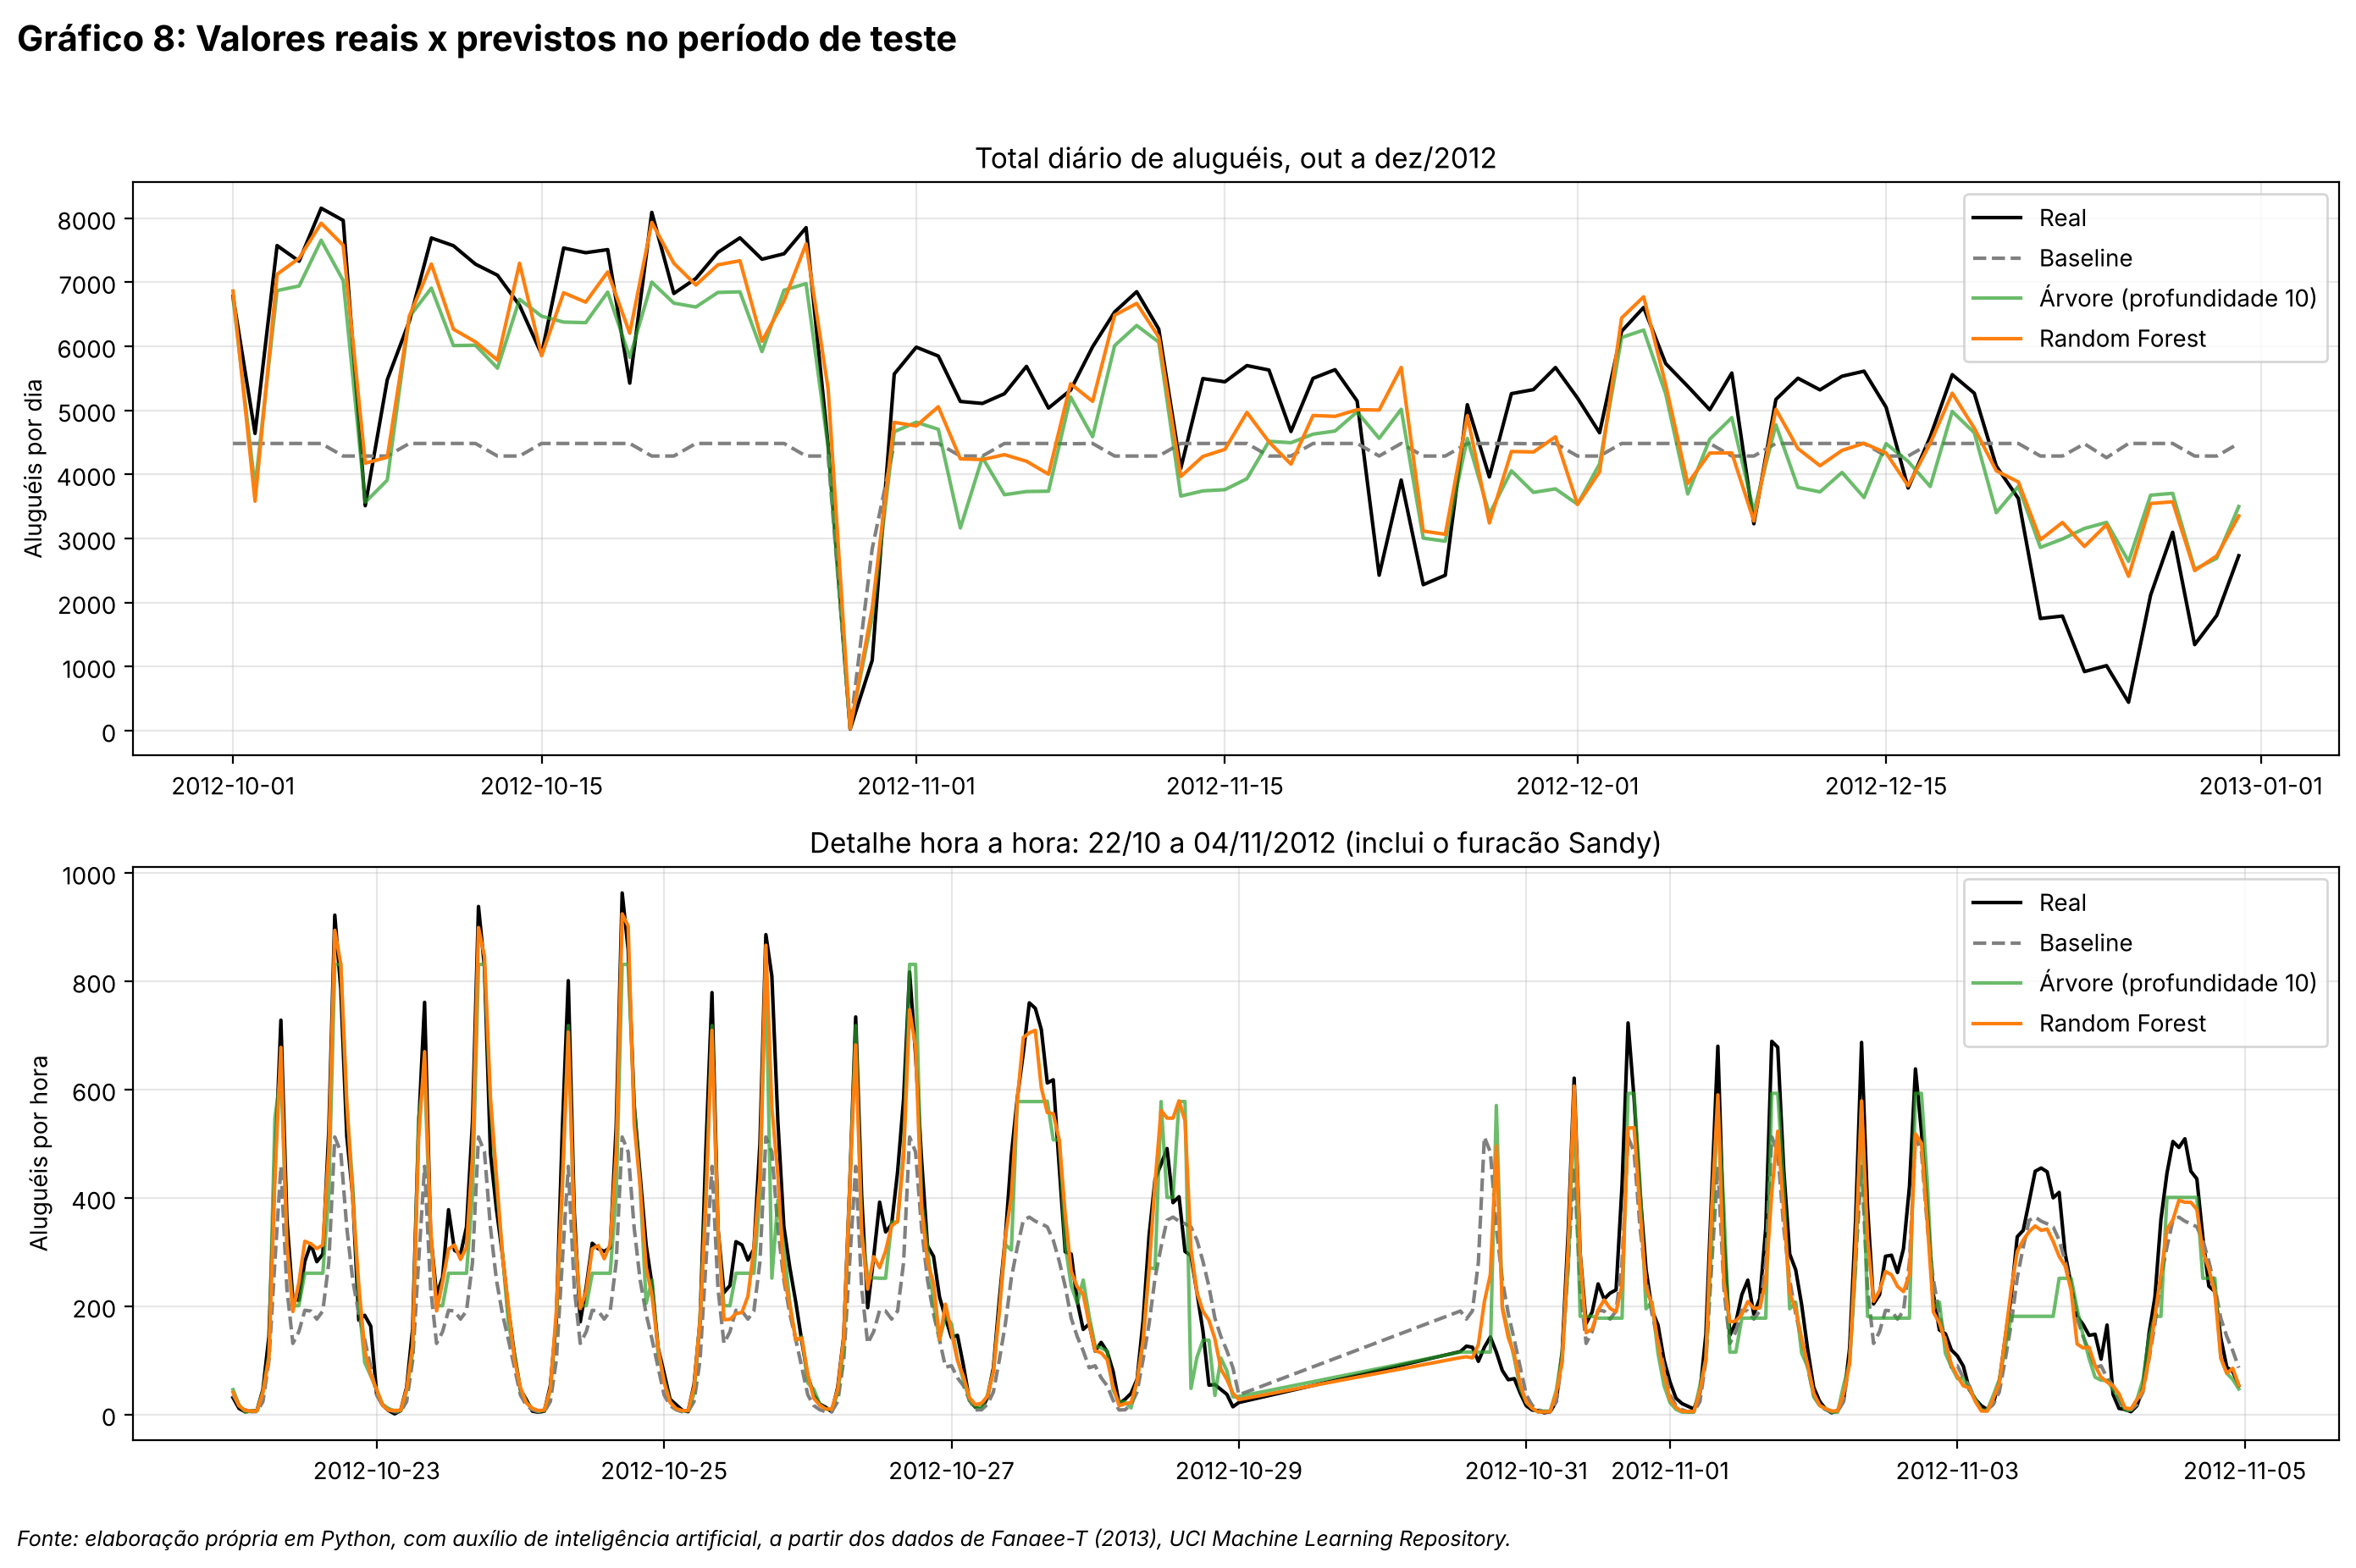

In [ ]:
# Número do gráfico no relatório
numero_grafico = 8

resultado = pd.DataFrame({
    'datahora': df_modelo.loc[~eh_treino, 'dteday'] + pd.to_timedelta(df_modelo.loc[~eh_treino, 'hr'], unit='h'),
    'real': y_teste,
    'baseline': prev_baseline,
    'arvore': arvore_final.predict(X_teste),
    'floresta': floresta.predict(X_teste),
})

por_dia = resultado.groupby(resultado['datahora'].dt.date)[['real', 'baseline', 'arvore', 'floresta']].sum()
semanas = resultado[(resultado['datahora'] >= '2012-10-22') & (resultado['datahora'] < '2012-11-05')]

fig, eixos = plt.subplots(2, 1, figsize=(14, 9))
for eixo, dados, x in [(eixos[0], por_dia, por_dia.index), (eixos[1], semanas, semanas['datahora'])]:
    eixo.plot(x, dados['real'], label='Real', color='black', linewidth=1.5)
    eixo.plot(x, dados['baseline'], label='Baseline', linestyle='--', color='gray')
    eixo.plot(x, dados['arvore'], label='Árvore (profundidade 10)', color='tab:green', alpha=0.7)
    eixo.plot(x, dados['floresta'], label='Random Forest', color='tab:orange')
    eixo.legend()
    eixo.grid(alpha=0.3)

eixos[0].set_title('Total diário de aluguéis, out a dez/2012')
eixos[0].set_ylabel('Aluguéis por dia')
eixos[1].set_title('Detalhe hora a hora: 22/10 a 04/11/2012 (inclui o furacão Sandy)')
eixos[1].set_ylabel('Aluguéis por hora')
fig.suptitle(f'Gráfico {numero_grafico}: Valores reais x previstos no período de teste',
             fontsize=15, fontweight='bold', x=0.01, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.96])
nota_grafico()
plt.savefig(f'figuras/grafico_{numero_grafico}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Número da tabela no relatório
numero_tabela = 5

# Viés das previsões diárias da Random Forest por mês do teste
teste_dia = resultado.groupby(resultado['datahora'].dt.date)[['real', 'floresta']].sum()
teste_dia.index = pd.to_datetime(teste_dia.index)
teste_dia['erro'] = teste_dia['floresta'] - teste_dia['real']
teste_dia['abaixo'] = teste_dia['floresta'] < teste_dia['real']

por_mes = teste_dia.groupby(teste_dia.index.month).agg(
    dias_abaixo=('abaixo', 'mean'),
    erro_medio=('erro', 'mean')
)
por_mes.index = por_mes.index.map({10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'})
por_mes.index.name = 'Mês'
por_mes.columns = ['Dias com previsão abaixo do real', 'Erro médio diário (previsto − real)']

# Exportar para o relatório
por_mes.round(3).to_csv(f'tabelas/tabela_{numero_tabela}.csv')

tabela_exibida = por_mes.style.format({
    'Dias com previsão abaixo do real': lambda v: f'{v * 100:.0f}%',
    'Erro médio diário (previsto − real)': lambda v: f'{v:+.0f}',
}).set_caption(f'Tabela {numero_tabela}: Viés das previsões diárias da Random Forest por mês do teste.')

display(tabela_exibida)
display(Markdown(f'*{FONTE}*'))


,Dias com previsão abaixo do real,Erro médio diário (previsto − real)
Mês,,
Outubro,68%,-284
Novembro,83%,-421
Dezembro,52%,+53


*Fonte: elaboração própria em Python, com auxílio de inteligência artificial, a partir dos dados de Fanaee-T (2013), UCI Machine Learning Repository.*

In [ ]:
## Em média, a Random Forest erra 47 bicicletas por hora, comparando com o baseline (que erra 80), o erro caiu cerca de 41%.
## Comparado com a melhor árvore sozinha (que erra 56,8), caiu cerca de 17%.

## R² = 0,872 nos diz que o modelo explica 87% da variação da demanda no período de teste.

## RMSE = 72.0 (valor menor que 88.1) nos diz que essa floresta não só erra menos, mas que também comete menos "erros grandes".

In [ ]:
##### Desempenho da Random Forest:

## A Random Forest, com 200 árvores, obteve o melhor desempenho no teste (MAE = 46,9; RMSE = 72,0; R² = 0,872), reduzindo o erro médio
## em cerca de 41% em relação ao baseline e em cerca de 17% em relação à melhor Árvore de Decisão. A combinação de muitas árvores treinadas em amostras
## diferentes reduz a instabilidade observada no modelo de árvore única.

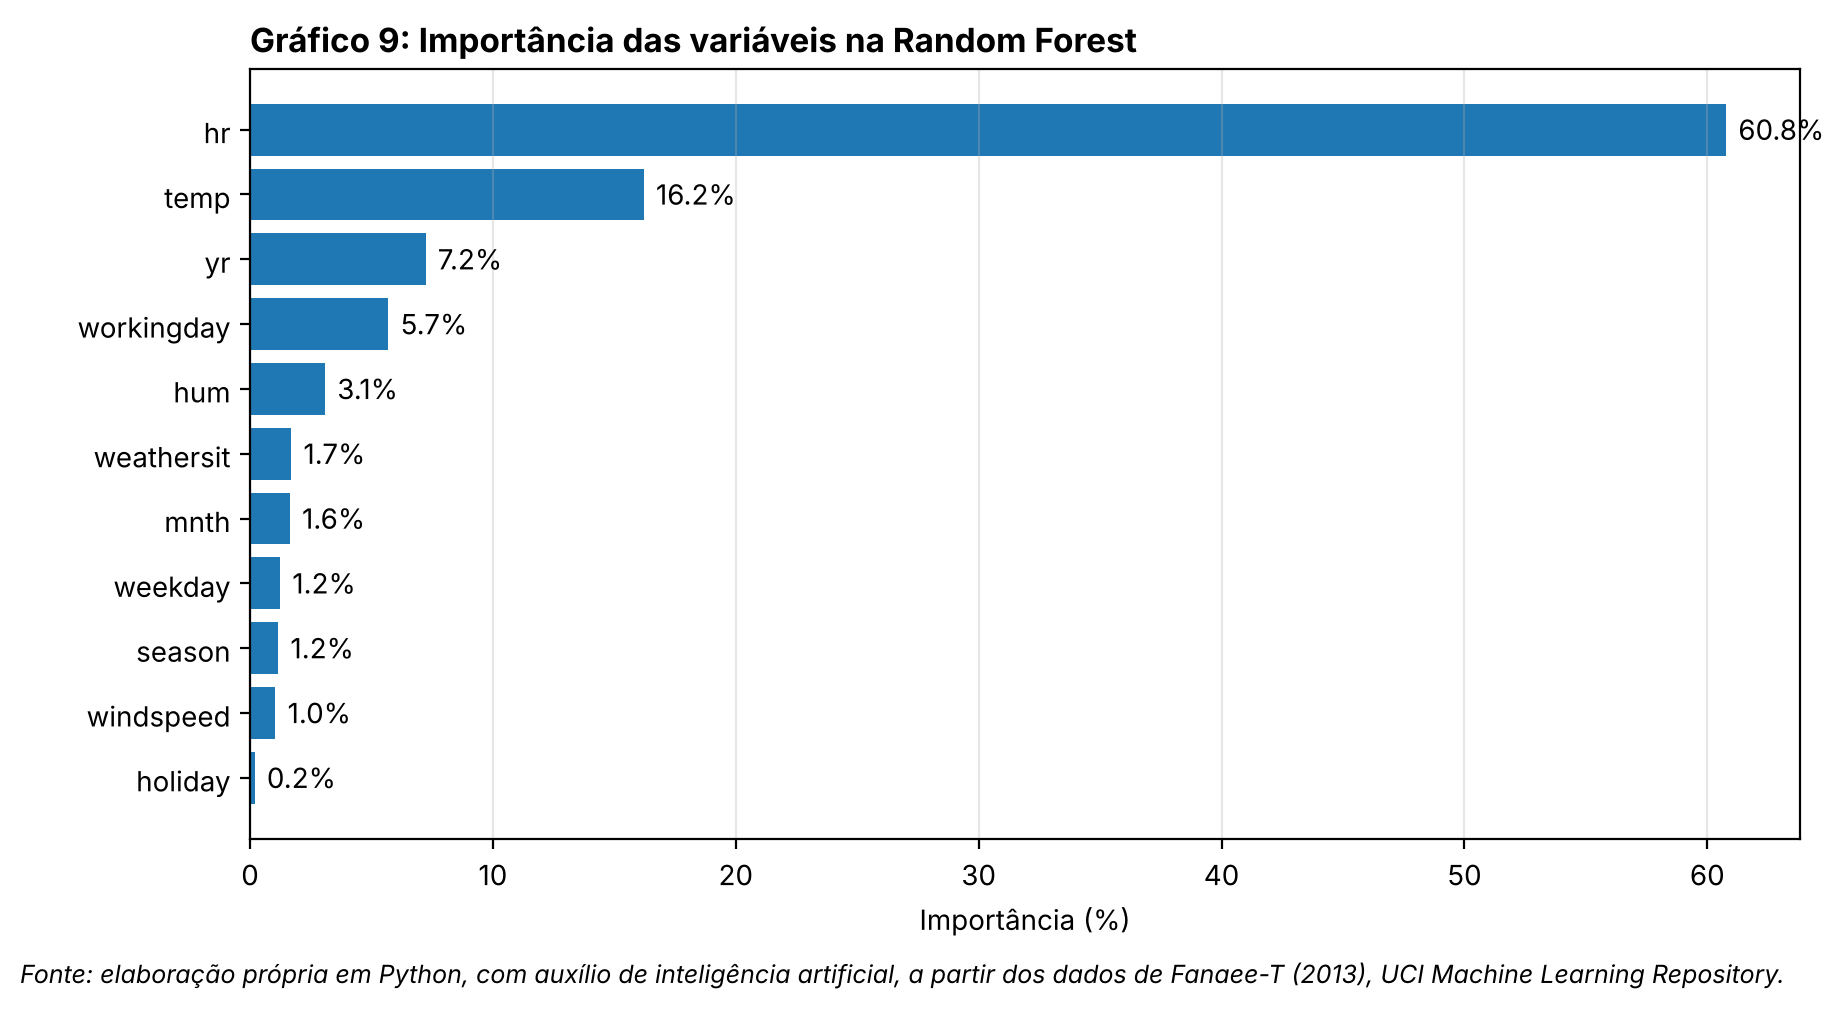

In [ ]:
# Número do gráfico no relatório
numero_grafico = 9

# Importância de cada variável, da maior para a menor
importancias = pd.Series(floresta.feature_importances_, index=colunas_entrada)
importancias = importancias.sort_values()

plt.figure(figsize=(10, 5))
plt.barh(importancias.index, importancias.values * 100)
plt.title(f'Gráfico {numero_grafico}: Importância das variáveis na Random Forest',
          fontweight='bold', loc='left')
plt.xlabel('Importância (%)')
plt.grid(alpha=0.3, axis='x')

# Escrever o valor ao lado de cada barra
for i, valor in enumerate(importancias.values * 100):
    plt.text(valor + 0.5, i, f'{valor:.1f}%', va='center')

nota_grafico()
plt.savefig(f'figuras/grafico_{numero_grafico}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
## Interpretação da importância:

## As variáveis mais importantes para a Random Forest foram a hora do dia (60,8%), a temperatura (16,2%), o ano (7,2%) e o indicador de dia útil (5,7%),
## em concordância com os padrões identificados na análise exploratória. A estação do ano teve importância baixa (1,2%), provavelmente porque sua informação
## já é capturada, de forma mais precisa, pela temperatura e pelo mês. Vale notar que essa medida de importância é calculada nos dados de treino e
## tende a favorecer variáveis com muitos valores distintos, como 'hr' e 'temp'.

# Comparando os resultados finais:

In [ ]:
# Número da tabela no relatório
numero_tabela = 6

# Previsões de cada modelo no teste
previsoes = {
    'Baseline (média por hora e tipo de dia)': prev_baseline,
    'Árvore de Decisão (sem limite)': arvore_livre.predict(X_teste),
    'Árvore de Decisão (profundidade 10)': arvore_final.predict(X_teste),
    'Random Forest (200 árvores)': floresta.predict(X_teste),
}

# Calcular as métricas de cada modelo
linhas = []
for modelo, prev in previsoes.items():
    linhas.append({
        'Modelo': modelo,
        'MAE': mean_absolute_error(y_teste, prev),
        'RMSE': np.sqrt(mean_squared_error(y_teste, prev)),
        'R²': r2_score(y_teste, prev),
    })

tabela_modelos = pd.DataFrame(linhas).set_index('Modelo')

# Quanto cada modelo reduziu o erro em relação ao baseline
mae_base = tabela_modelos.loc['Baseline (média por hora e tipo de dia)', 'MAE']
tabela_modelos['Redução do MAE vs. baseline'] = (1 - tabela_modelos['MAE'] / mae_base) * 100

# Exibir formatado, com o melhor resultado de cada métrica em negrito
# Exportar para o relatório
tabela_modelos.round(3).to_csv(f'tabelas/tabela_{numero_tabela}.csv')

tabela_exibida = tabela_modelos.style.format({
    'MAE': lambda v: f'{v:.1f}'.replace('.', ','),
    'RMSE': lambda v: f'{v:.1f}'.replace('.', ','),
    'R²': lambda v: f'{v:.3f}'.replace('.', ','),
    'Redução do MAE vs. baseline': lambda v: f'{v:.0f}%',
}).highlight_min(
    subset=['MAE', 'RMSE'], props='font-weight: bold'
).highlight_max(
    subset=['R²'], props='font-weight: bold'
).set_caption(
    f'Tabela {numero_tabela}: Desempenho dos modelos no período de teste (out a dez/2012).'
)

display(tabela_exibida)
display(Markdown(f'*{FONTE}*'))


,MAE,RMSE,R²,Redução do MAE vs. baseline
Modelo,,,,
Baseline (média por hora e tipo de dia),"80,0","119,6","0,648",0%
Árvore de Decisão (sem limite),"56,8","88,1","0,809",29%
Árvore de Decisão (profundidade 10),"60,4","94,6","0,780",24%
Random Forest (200 árvores),"46,9","72,0","0,872",41%


*Fonte: elaboração própria em Python, com auxílio de inteligência artificial, a partir dos dados de Fanaee-T (2013), UCI Machine Learning Repository.*

In [ ]:
print(f'Demanda média no teste: {y_teste.mean():.1f} bicicletas por hora')

Demanda média no teste: 219.2 bicicletas por hora


In [ ]:
# Comparação Final:

# Os três modelos de aprendizado de máquina superaram o baseline, o que indica que as variáveis de clima e calendário acrescentam informação além do padrão horário.
# A Random Forest teve o melhor resultado em todas as métricas, com erro médio de 46,9 bicicletas por hora, cerca de 21% da demanda média do período de teste,
# contra cerca de 37% do baseline. A árvore com profundidade 10 teve desempenho inferior à árvore sem limite, o que confirma a instabilidade
# da escolha de hiperparâmetros em uma árvore única. Em todos os modelos, o RMSE ficou cerca de 1,5 vez acima do MAE, indicando a presença de erros pontuais maiores,
# associados a períodos atípicos.

# ---------- Limitações ----------

O principal limite do projeto vem do próprio tipo de modelo. Árvores de decisão e Random Forest não conseguem prever valores maiores do que os que aparecem no treino. Isso pesou aqui porque a demanda subiu bastante de 2011 para 2012, e os únicos meses de outubro a dezembro que o modelo viu no treino são os de 2011. O Gráfico 8 mostra o efeito: em outubro e novembro de 2012, as previsões da Random Forest ficaram abaixo do valor real na maioria dos dias (68% e 83% deles). No fim de dezembro o efeito se inverte: com a queda de demanda das festas, o modelo previu acima do real. Se o sistema continuasse crescendo, o modelo teria que ser retreinado com frequência para acompanhar.

Também é preciso lembrar que os dados cobrem só dois anos de uma cidade, Washington, numa fase em que o serviço ainda estava se expandindo. Não dá para garantir que os mesmos padrões, como os picos no horário de trabalho e a queda no frio, valham para outra cidade ou para um sistema já consolidado.

Alguns acontecimentos não têm como ser previstos com essas variáveis, como o furacão Sandy ou uma tempestade forte. Além disso, faltam 165 horas na base, a maioria por paradas no serviço, e optamos por não preenchê-las.

Outro ponto é que usamos o clima que de fato aconteceu em cada hora. Se o modelo fosse usado para prever a demanda do dia seguinte, ele teria que trabalhar com a previsão do tempo, que também erra. Na prática, o desempenho provavelmente seria um pouco pior do que o medido no teste.

Sobre a escolha dos parâmetros: a profundidade da árvore foi definida com um único período de validação, de julho a setembro de 2012, e a diferença entre as profundidades de 10 para cima foi menor que 2 bicicletas. Tanto que, no teste, a árvore sem limite acabou se saindo melhor que a de profundidade 10. A Random Forest foi usada com 200 árvores e as demais configurações no padrão, sem nenhum ajuste.

Por fim, o teste cobre só um trimestre. Avaliar o modelo em mais de um período daria uma ideia mais confiável de como ele se comporta.

Como próximos passos, valeria incluir variáveis com a demanda das horas anteriores, tratar a tendência de crescimento separadamente, ajustar os parâmetros da Random Forest com validação cruzada temporal (TimeSeriesSplit), prever log(1 + cnt) em vez de cnt e comparar com outros modelos, como o gradient boosting


#  ---------- Conclusão ----------

O objetivo do trabalho era prever quantas bicicletas são alugadas por hora no Capital Bikeshare, usando informações de calendário e de clima.

Na verificação inicial, a base parecia perfeita: nenhum valor nulo e nenhuma linha repetida. Olhando com mais cuidado, apareceram alguns problemas. A umidade estava zerada no dia 10/03/2011, a sensação térmica ficou travada no mesmo valor em 17/08/2012, uma das categorias de clima tinha só 3 registros e faltavam 165 horas, quase todas ligadas a paradas no serviço, como no furacão Sandy. Cada um desses casos foi tratado ou documentado antes da modelagem.

A análise exploratória mostrou que a hora do dia é o que mais muda a demanda. Nos dias úteis há dois picos, às 8h e entre 17h e 18h, o que bate com o horário de ida e volta do trabalho. Nos fins de semana, o uso se concentra entre 12h e 17h, mais com cara de passeio. Vimos também que as pessoas alugam menos no inverno e mais no verão, que a demanda acompanha a temperatura até uns 20 a 30 °C e depois cai, e que de 2011 para 2012 o número de aluguéis cresceu cerca de 63%.

Para a modelagem, separamos os dados pela data: o treino foi de janeiro de 2011 a setembro de 2012, e o teste, de outubro a dezembro de 2012. A Random Forest teve o melhor resultado, com MAE de 46,9, RMSE de 72,0 e R² de 0,872. Em média, ela errou 47 bicicletas por hora, contra 80 do modelo de referência (cerca de 41% a menos) e 56,8 da melhor árvore de decisão (cerca de 17% a menos). A árvore sozinha decorava os dados de treino e era sensível à escolha da profundidade, e juntar várias árvores resolveu boa parte disso.

As variáveis que a Random Forest mais usou foram a hora (60,8%), a temperatura (16,2%), o ano (7,2%) e o indicador de dia útil (5,7%), as mesmas que já tinham se destacado na análise exploratória. A estação do ano ficou com só 1,2%. Isso não quer dizer que ela não influencie a demanda. Provavelmente, a informação que ela carrega já chega ao modelo pela temperatura e pelo mês, que são mais precisos.

No geral, a demanda por bicicletas é bem explicada pelo horário, pelo tipo de dia, pelo ano e pela temperatura, e a Random Forest se mostrou uma boa escolha para prevê-la. O principal cuidado é que o modelo não acompanha o crescimento do sistema, então precisaria ser retreinado de tempos em tempos para continuar útil.